In [1]:
# Spotlight - Interest Model
# Notebook 03

import pandas as pd
import numpy as np

print("Interest model notebook ready!")

Interest model notebook ready!


In [2]:
# Load data for the interest model

small_matrix = pd.read_csv("../data/small_matrix.csv")
item_features = pd.read_csv("../data/item_daily_features.csv")

# Create the same engagement score used in our baseline
small_matrix["watch_score"] = small_matrix["watch_ratio"].clip(upper=3.0)

# Clean dates using the correct YYYYMMDD format
small_matrix = small_matrix.dropna(subset=["date"]).copy()

small_matrix["date"] = pd.to_datetime(
    small_matrix["date"].astype(int).astype(str),
    format="%Y%m%d"
)

# Use the same temporal split as Notebook 02
train_end = pd.Timestamp("2020-08-29")

train_data = small_matrix[
    small_matrix["date"] <= train_end
].copy()

test_data = small_matrix[
    small_matrix["date"] > train_end
].copy()

print("Training interactions:", len(train_data))
print("Testing interactions:", len(test_data))
print("Training users:", train_data["user_id"].nunique())
print("Training videos:", train_data["video_id"].nunique())

print("\nItem feature rows:", len(item_features))
print("Videos with tags:",
      item_features["video_tag_name"].notna().sum())

Training interactions: 4387382
Testing interactions: 107196
Training users: 1411
Training videos: 3288

Item feature rows: 343341
Videos with tags: 310907


In [3]:
# Create a clean video-to-tag mapping

video_tags = (
    item_features[
        ["video_id", "video_tag_name"]
    ]
    .dropna(subset=["video_tag_name"])
    .drop_duplicates("video_id")
)

# Keep only videos that appear in our interaction dataset
interaction_videos = small_matrix["video_id"].unique()

video_tags = video_tags[
    video_tags["video_id"].isin(interaction_videos)
].copy()

print("Videos in interaction dataset:", len(interaction_videos))
print("Videos with tags:", video_tags["video_id"].nunique())
print("Unique tags:", video_tags["video_tag_name"].nunique())

print("\nSample video-tag mapping:")
print(video_tags.head(10))

Videos in interaction dataset: 3327
Videos with tags: 3324
Unique tags: 346

Sample video-tag mapping:
      video_id video_tag_name
5805       103             面食
6147       109            摩托车
6785       120             搞笑
6852       122              猴
7273       128             美食
7328       130             侧面
7391       131           电影黑条
7517       133              猫
7706       136           人群聚集
7769       137           影视介绍


In [4]:
# Build the interest profile for User 14

target_user_id = 14

# Get User 14's training interactions
user_history = train_data[
    train_data["user_id"] == target_user_id
].copy()

# Attach video tags
user_history_tags = user_history.merge(
    video_tags,
    on="video_id",
    how="left"
)

# Remove interactions without a tag
user_history_tags = user_history_tags.dropna(
    subset=["video_tag_name"]
)

# Calculate engagement for each tag
user_interest = (
    user_history_tags
    .groupby("video_tag_name")
    .agg(
        interactions=("video_id", "count"),
        avg_watch_score=("watch_score", "mean")
    )
    .sort_values(
        "avg_watch_score",
        ascending=False
    )
)

print("User 14 training interactions:", len(user_history))
print("Tagged interactions:", len(user_history_tags))
print("\nTop 20 interests for User 14:")
print(user_interest.head(20))

User 14 training interactions: 3158
Tagged interactions: 3155

Top 20 interests for User 14:
                interactions  avg_watch_score
video_tag_name                               
轮滑                         1         3.000000
聊天截屏                       1         3.000000
工作场所                       1         3.000000
卖包                         1         2.559088
盆栽                         1         2.319912
孕妇知识                       3         2.094331
猴子                         2         2.038340
交通工具                       2         1.949438
穴位按摩                       3         1.902452
键盘                         1         1.872951
饮料                         3         1.848015
养蜂                         1         1.816010
影视介绍                       2         1.704001
水饺                         1         1.681746
软件教学                       1         1.667741
字幕遮脸                       3         1.609334
乡村女                        1         1.605414
娱乐场所                       3     

In [5]:
# Calculate a smoothed interest score for User 14

# User's overall average engagement
user_mean = user_history["watch_score"].mean()

# Smoothing strength
smoothing = 5

user_interest["smoothed_interest"] = (
    (
        user_interest["interactions"] * user_interest["avg_watch_score"]
        + smoothing * user_mean
    )
    /
    (
        user_interest["interactions"] + smoothing
    )
)

# Sort by smoothed interest
user_interest = user_interest.sort_values(
    "smoothed_interest",
    ascending=False
)

print("User 14 overall average watch score:",
      round(user_mean, 4))

print("\nTop 20 interests after smoothing:")
print(user_interest.head(20))

User 14 overall average watch score: 0.9483

Top 20 interests after smoothing:
                interactions  avg_watch_score  smoothed_interest
video_tag_name                                                  
孕妇知识                       3         2.094331           1.378070
穴位按摩                       3         1.902452           1.306115
聊天截屏                       1         3.000000           1.290261
轮滑                         1         3.000000           1.290261
工作场所                       1         3.000000           1.290261
饮料                         3         1.848015           1.285701
猴子                         2         2.038340           1.259749
交通工具                       2         1.949438           1.234349
卖包                         1         2.559088           1.216776
字幕遮脸                       3         1.609334           1.196196
篮球_篮球场                    23         1.247504           1.194077
娱乐场所                       3         1.593294           1.190181
三农         

C:\Users\Shrutee Patil\AppData\Local\Temp\ipykernel_20616\422038412.py:20: UserWarning: Glyph 30406 (\N{CJK UNIFIED IDEOGRAPH-76C6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Shrutee Patil\AppData\Local\Temp\ipykernel_20616\422038412.py:20: UserWarning: Glyph 26685 (\N{CJK UNIFIED IDEOGRAPH-683D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Shrutee Patil\AppData\Local\Temp\ipykernel_20616\422038412.py:20: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Shrutee Patil\AppData\Local\Temp\ipykernel_20616\422038412.py:20: UserWarning: Glyph 27963 (\N{CJK UNIFIED IDEOGRAPH-6D3B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Shrutee Patil\AppData\Local\Temp\ipykernel_20616\422038412.py:20: UserWarning: Glyph 19977 (\N{CJK UNIFIED IDEOGRAPH-4E09}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Shrutee Patil\AppData\Local\Temp\ipykernel_20616\42

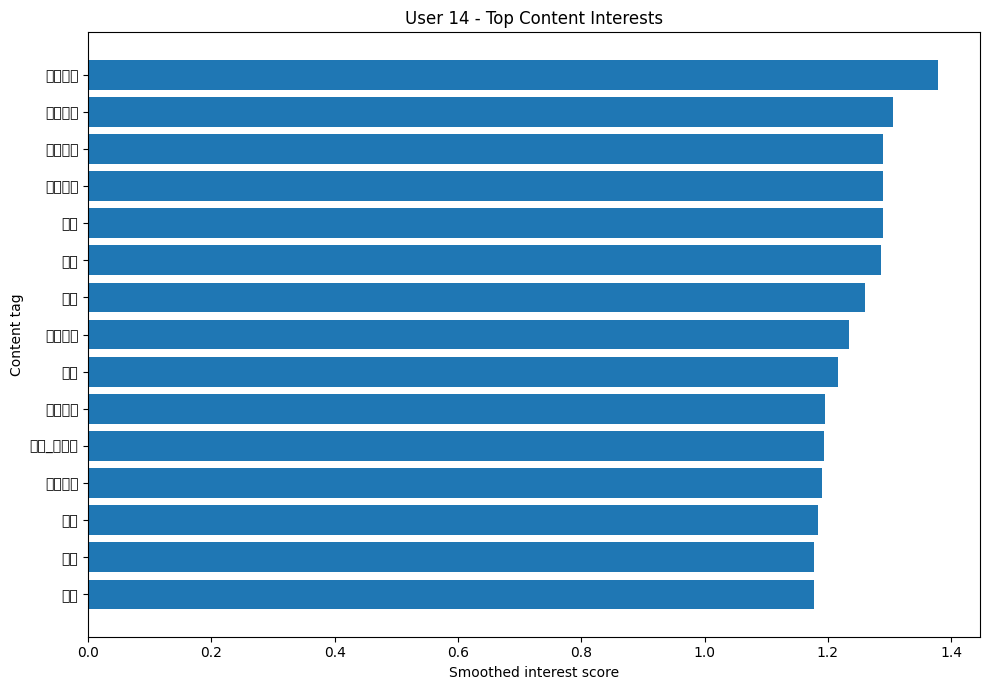

In [6]:
import matplotlib.pyplot as plt

top_interests = (
    user_interest
    .head(15)
    .sort_values("smoothed_interest")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_interests.index,
    top_interests["smoothed_interest"]
)

plt.xlabel("Smoothed interest score")
plt.ylabel("Content tag")
plt.title("User 14 - Top Content Interests")

plt.tight_layout()
plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not foun

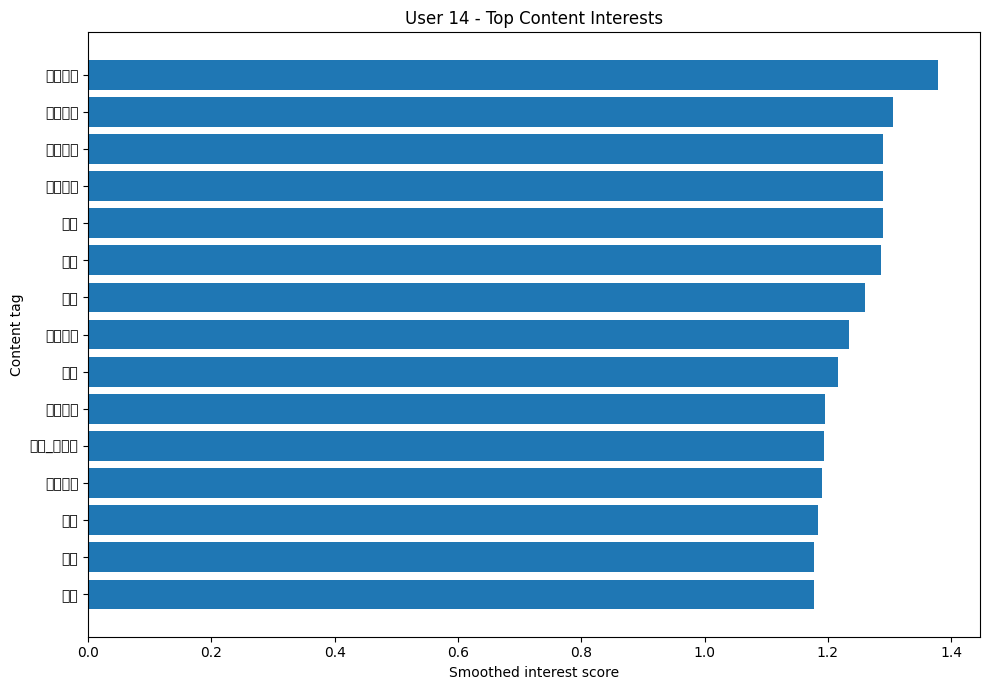

In [7]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

top_interests = (
    user_interest
    .head(15)
    .sort_values("smoothed_interest")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_interests.index,
    top_interests["smoothed_interest"]
)

plt.xlabel("Smoothed interest score")
plt.ylabel("Content tag")
plt.title("User 14 - Top Content Interests")

plt.tight_layout()
plt.show()

In [8]:
import matplotlib.font_manager as fm

fonts = fm.findSystemFonts()

for font in fonts:
    if any(name in font.lower() for name in ["noto", "cjk", "msyh", "yahei", "simsun"]):
        print(font)

C:\Windows\Fonts\simsunb.ttf
C:\Windows\Fonts\msyhbd.ttc
C:\Windows\Fonts\SimsunExtG.ttf
C:\Windows\Fonts\msyhl.ttc
C:\Windows\Fonts\msyh.ttc
C:\Windows\Fonts\simsun.ttc


findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not foun

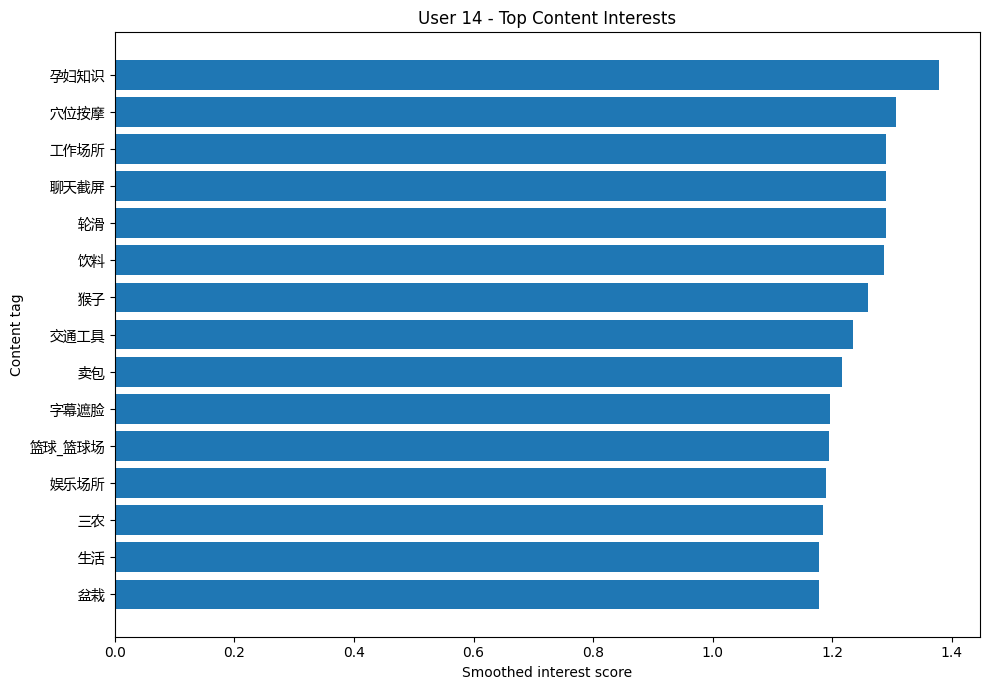

In [9]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Use Microsoft YaHei for Chinese text
font_path = r"C:\Windows\Fonts\msyh.ttc"
font_prop = fm.FontProperties(fname=font_path)

top_interests = (
    user_interest
    .head(15)
    .sort_values("smoothed_interest")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_interests.index,
    top_interests["smoothed_interest"]
)

plt.xlabel("Smoothed interest score")
plt.ylabel("Content tag")
plt.title("User 14 - Top Content Interests")

# Apply Chinese-compatible font to the y-axis labels
plt.yticks(fontproperties=font_prop)

plt.tight_layout()
plt.show()

In [10]:
# Get all unique content tags used in our experiment

all_tags = (
    video_tags["video_tag_name"]
    .dropna()
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

print("Total unique tags:", len(all_tags))

display(
    pd.DataFrame({
        "tag_id": range(1, len(all_tags) + 1),
        "original_tag": all_tags
    })
)

Total unique tags: 346


,tag_id,original_tag
0,1,UNKNOWN
1,2,一盘菜
2,3,三农
3,4,两性情感
4,5,个性定制
...,...,...
341,342,鸽子
342,343,鹿
343,344,麻将
344,345,黄瓜


In [11]:
for i, tag in enumerate(all_tags.iloc[0:100], start=1):
    print(f"{i:3}. {tag}")

  1. UNKNOWN
  2. 一盘菜
  3. 三农
  4. 两性情感
  5. 个性定制
  6. 乌龟
  7. 乐器
  8. 乡村
  9. 乡村女
 10. 书法
 11. 事故
 12. 二维码
 13. 交通工具
 14. 亲子
 15. 人
 16. 人-女
 17. 人群聚集
 18. 伤感
 19. 体育运动
 20. 侧面
 21. 停车场
 22. 健康
 23. 健身
 24. 健身房
 25. 兔
 26. 公交内部
 27. 公交车
 28. 其它动物
 29. 养发护发
 30. 养水族
 31. 养蜂
 32. 内饰
 33. 军警
 34. 军训
 35. 农业
 36. 农村
 37. 农田
 38. 冰淇淋
 39. 减肥
 40. 创业广告
 41. 制作食物
 42. 动漫
 43. 动物
 44. 包子
 45. 化妆
 46. 医疗_骨科
 47. 医院
 48. 卖包
 49. 卖电子设备广告
 50. 卖衣服
 51. 卖鞋
 52. 卡车
 53. 历史
 54. 厨师烹饪
 55. 友情
 56. 双胞胎
 57. 古装拍戏
 58. 台球
 59. 吃东西
 60. 吃播
 61. 吃鸡游戏
 62. 听书
 63. 咖啡
 64. 唱歌
 65. 国外
 66. 国画_水墨画
 67. 土豆
 68. 地名
 69. 地铁内部
 70. 坦克_装甲车
 71. 城市夜景
 72. 塔
 73. 壁纸
 74. 壮年女
 75. 壮年男
 76. 声控
 77. 夜景
 78. 大叔
 79. 大妈
 80. 大桌饭
 81. 大棚
 82. 大象
 83. 天气好
 84. 天空
 85. 头巾_帽子
 86. 女-全身
 87. 女-半身
 88. 女-半身-清纯
 89. 女-清纯
 90. 女-清纯-户外
 91. 女-美腿
 92. 女孩
 93. 女青年
 94. 奶奶
 95. 娱乐
 96. 娱乐场所
 97. 婚庆广告
 98. 婚礼
 99. 婴儿
100. 孕妇知识


In [12]:
for i, tag in enumerate(all_tags.iloc[100:200], start=101):
    print(f"{i:3}. {tag}")
    

101. 字幕遮脸
102. 学生
103. 宝妈
104. 宠物
105. 室内
106. 室内装修
107. 家庭关系
108. 小孩
109. 小鲜肉
110. 小鲜肉-齐刘海
111. 少女
112. 少男
113. 屋顶俯瞰
114. 屏幕
115. 山水风景
116. 山脉
117. 工作场所
118. 幼儿教育
119. 床
120. 建筑
121. 开心
122. 开箱
123. 影视介绍
124. 影视作品
125. 心灵鸡汤
126. 恶心
127. 悼念
128. 情感
129. 截图
130. 户外
131. 手势
132. 手势舞
133. 手工制品
134. 手控
135. 手机
136. 手机技巧
137. 手绘
138. 才艺
139. 扮丑
140. 护肤
141. 挖掘机
142. 搞笑
143. 摄影
144. 摩托车
145. 操场
146. 教室
147. 教育
148. 文字控
149. 文玩
150. 文玩珠宝广告
151. 文艺男神
152. 新生儿
153. 方向盘
154. 旅游
155. 旅游景点
156. 日出_日落
157. 明星
158. 晨昏
159. 晴天
160. 服装
161. 服装店
162. 机车
163. 杯子
164. 果蔬
165. 树
166. 树木
167. 格斗
168. 椅子
169. 植物
170. 植物养殖
171. 模糊
172. 正面
173. 步伐
174. 武术
175. 段子
176. 比萨
177. 毕业
178. 毛绒玩具
179. 气球
180. 水塘_池塘
181. 水果
182. 水生动物
183. 水饺
184. 汉堡
185. 汉服
186. 汽车
187. 沙漠
188. 法律知识
189. 泥
190. 泳池
191. 海边_沙滩
192. 海鲜
193. 清晰
194. 温馨
195. 游乐场
196. 游戏
197. 火灾
198. 火锅
199. 烧烤
200. 烹饪教程


In [13]:
for i, tag in enumerate(all_tags.iloc[200:300], start=201):
    print(f"{i:3}. {tag}")

201. 熊猫
202. 爬宠
203. 爱情
204. 爷爷
205. 牛
206. 牛仔裤
207. 物体
208. 狗
209. 猪
210. 猫
211. 猴
212. 猴子
213. 玉石
214. 玉米
215. 玩具
216. 玩泥
217. 球类运动
218. 瑜伽
219. 瓶子
220. 甜品
221. 生活
222. 生活清洁
223. 电工
224. 电影黑条
225. 电梯
226. 电脑
227. 男孩
228. 男青年
229. 瘦身操
230. 盆栽
231. 盘子
232. 直播截图
233. 直播截屏
234. 相声
235. 眼妆
236. 社会摇
237. 祝福
238. 秀胸
239. 科学
240. 穴位按摩
241. 穿戴
242. 穿搭
243. 穿衣秀
244. 窗帘
245. 篮球
246. 篮球_篮球场
247. 篮球场
248. 米饭
249. 糖
250. 绘画
251. 编发
252. 羊
253. 羊驼
254. 美发
255. 美发教程
256. 美妆广告
257. 美食
258. 翘臀
259. 老人
260. 聊天截屏
261. 育儿知识
262. 背面
263. 自拍脸
264. 自然场景
265. 自由旅行
266. 自行车
267. 舞台
268. 舞台表演
269. 舞蹈
270. 航拍
271. 花
272. 花圃_花海
273. 花生
274. 范冰冰
275. 草莓
276. 萨克斯
277. 虾
278. 蛇
279. 蛋糕
280. 行为-吃喝
281. 街头健身
282. 街机游戏
283. 街舞
284. 表情包
285. 西点
286. 西瓜
287. 西红柿
288. 警察
289. 证书
290. 话筒
291. 谷物丰收
292. 豪车
293. 资讯
294. 走路
295. 超市
296. 越野车
297. 跆拳道
298. 跳舞
299. 身份证
300. 轮滑


In [14]:
for i, tag in enumerate(all_tags.iloc[300:346], start=301):
    print(f"{i:3}. {tag}")

301. 轮滑滑板
302. 轮胎
303. 软件教学
304. 轿车内部
305. 辅导班招生广告
306. 辣
307. 辣椒
308. 运动
309. 迪丽热巴
310. 速算教程
311. 道路
312. 邓超
313. 钓鱼
314. 钢琴
315. 钱
316. 锅
317. 键盘
318. 镜子
319. 雨
320. 雪地
321. 面部画妆
322. 面食
323. 音乐
324. 音乐分享
325. 颜值
326. 飞机
327. 食品类广告
328. 食物
329. 饮品
330. 饮料
331. 饼
332. 马
333. 骆驼
334. 高尔夫球
335. 高档汽车
336. 高楼
337. 魔术
338. 魔术教学
339. 鱼
340. 鲜花
341. 鸭_鹅
342. 鸽子
343. 鹿
344. 麻将
345. 黄瓜
346. 鼠


In [15]:
# English translation mapping for all 346 KuaiRec content tags

tag_translation = {
    "UNKNOWN": "Unknown",
    "一盘菜": "Dish / Plate of Food",
    "三农": "Agriculture & Rural Affairs",
    "两性情感": "Relationships & Sexuality",
    "个性定制": "Personalized Customization",
    "乌龟": "Turtle",
    "乐器": "Musical Instruments",
    "乡村": "Countryside",
    "乡村女": "Rural Woman",
    "书法": "Calligraphy",
    "事故": "Accident",
    "二维码": "QR Code",
    "交通工具": "Transportation",
    "亲子": "Parent & Child",
    "人": "Person",
    "人-女": "Woman",
    "人群聚集": "Crowd Gathering",
    "伤感": "Sadness / Emotional",
    "体育运动": "Sports",
    "侧面": "Side View",
    "停车场": "Parking Lot",
    "健康": "Health",
    "健身": "Fitness",
    "健身房": "Gym",
    "兔": "Rabbit",
    "公交内部": "Inside Bus",
    "公交车": "Bus",
    "其它动物": "Other Animals",
    "养发护发": "Hair Care",
    "养水族": "Aquarium / Fish Keeping",
    "养蜂": "Beekeeping",
    "内饰": "Interior",
    "军警": "Military & Police",
    "军训": "Military Training",
    "农业": "Agriculture",
    "农村": "Rural Areas",
    "农田": "Farmland",
    "冰淇淋": "Ice Cream",
    "减肥": "Weight Loss",
    "创业广告": "Entrepreneurship Advertisement",
    "制作食物": "Food Preparation",
    "动漫": "Anime & Animation",
    "动物": "Animals",
    "包子": "Steamed Buns",
    "化妆": "Makeup",
    "医疗_骨科": "Medical / Orthopedics",
    "医院": "Hospital",
    "卖包": "Bag Selling",
    "卖电子设备广告": "Electronic Device Advertisement",
    "卖衣服": "Clothing Sales",
    "卖鞋": "Shoe Sales",
    "卡车": "Truck",
    "历史": "History",
    "厨师烹饪": "Chef / Cooking",
    "友情": "Friendship",
    "双胞胎": "Twins",
    "古装拍戏": "Historical Costume Filming",
    "台球": "Billiards",
    "吃东西": "Eating",
    "吃播": "Mukbang",
    "吃鸡游戏": "PUBG / Battle Royale Game",
    "听书": "Audiobooks",
    "咖啡": "Coffee",
    "唱歌": "Singing",
    "国外": "Foreign / Overseas",
    "国画_水墨画": "Chinese Painting / Ink Wash Painting",
    "土豆": "Potato",
    "地名": "Place Name",
    "地铁内部": "Inside Subway",
    "坦克_装甲车": "Tank / Armored Vehicle",
    "城市夜景": "City Night View",
    "塔": "Tower",
    "壁纸": "Wallpaper",
    "壮年女": "Middle-Aged Woman",
    "壮年男": "Middle-Aged Man",
    "声控": "Voice-Controlled / Voice Content",
    "夜景": "Night View",
    "大叔": "Middle-Aged Man",
    "大妈": "Middle-Aged Woman",
    "大桌饭": "Large Shared Meal",
    "大棚": "Greenhouse",
    "大象": "Elephant",
    "天气好": "Good Weather",
    "天空": "Sky",
    "头巾_帽子": "Headscarf / Hat",
    "女-全身": "Woman - Full Body",
    "女-半身": "Woman - Upper Body",
    "女-半身-清纯": "Woman - Upper Body - Innocent",
    "女-清纯": "Woman - Innocent",
    "女-清纯-户外": "Woman - Innocent - Outdoor",
    "女-美腿": "Woman - Attractive Legs",
    "女孩": "Girl",
    "女青年": "Young Woman",
    "奶奶": "Grandmother",
    "娱乐": "Entertainment",
    "娱乐场所": "Entertainment Venue",
    "婚庆广告": "Wedding Advertisement",
    "婚礼": "Wedding",
    "婴儿": "Baby",
    "孕妇知识": "Pregnancy Knowledge",
    "字幕遮脸": "Face Covered by Subtitles",
    "学生": "Student",
    "宝妈": "Mother / Mom",
    "宠物": "Pets",
    "室内": "Indoor",
    "室内装修": "Interior Decoration",
    "家庭关系": "Family Relationships",
    "小孩": "Child",
    "小鲜肉": "Young Male Celebrity",
    "小鲜肉-齐刘海": "Young Male Celebrity - Straight Bangs",
    "少女": "Teenage Girl",
    "少男": "Teenage Boy",
    "屋顶俯瞰": "Rooftop Overlook",
    "屏幕": "Screen",
    "山水风景": "Mountain & Water Landscape",
    "山脉": "Mountains",
    "工作场所": "Workplace",
    "幼儿教育": "Early Childhood Education",
    "床": "Bed",
    "建筑": "Architecture / Buildings",
    "开心": "Happiness",
    "开箱": "Unboxing",
    "影视介绍": "Film & TV Introduction",
    "影视作品": "Film & TV Content",
    "心灵鸡汤": "Inspirational / Life Advice",
    "恶心": "Disgusting / Gross",
    "悼念": "Mourning / Memorial",
    "情感": "Emotions / Relationships",
    "截图": "Screenshot",
    "户外": "Outdoor",
    "手势": "Gestures",
    "手势舞": "Hand Gesture Dance",
    "手工制品": "Handmade Products",
    "手控": "Hand-Focused Content",
    "手机": "Mobile Phone",
    "手机技巧": "Mobile Phone Tips",
    "手绘": "Hand-Drawn Art",
    "才艺": "Talent",
    "扮丑": "Funny / Ugly Makeup",
    "护肤": "Skincare",
    "挖掘机": "Excavator",
    "搞笑": "Comedy / Funny",
    "摄影": "Photography",
    "摩托车": "Motorcycle",
    "操场": "Playground / Sports Field",
    "教室": "Classroom",
    "教育": "Education",
    "文字控": "Text-Focused Content",
    "文玩": "Collectibles",
    "文玩珠宝广告": "Collectibles & Jewelry Advertisement",
    "文艺男神": "Artistic / Refined Male",
    "新生儿": "Newborn",
    "方向盘": "Steering Wheel",
    "旅游": "Travel",
    "旅游景点": "Tourist Attractions",
    "日出_日落": "Sunrise / Sunset",
    "明星": "Celebrity",
    "晨昏": "Dawn / Dusk",
    "晴天": "Sunny Weather",
    "服装": "Clothing",
    "服装店": "Clothing Store",
    "机车": "Motorcycle / Motorbike",
    "杯子": "Cup",
    "果蔬": "Fruits & Vegetables",
    "树": "Tree",
    "树木": "Trees",
    "格斗": "Combat Sports / Fighting",
    "椅子": "Chair",
    "植物": "Plants",
    "植物养殖": "Plant Cultivation",
    "模糊": "Blurry",
    "正面": "Front View",
    "步伐": "Walking / Footsteps",
    "武术": "Martial Arts",
    "段子": "Comedy Skit / Joke",
    "比萨": "Pizza",
    "毕业": "Graduation",
    "毛绒玩具": "Plush Toys",
    "气球": "Balloons",
    "水塘_池塘": "Pond",
    "水果": "Fruits",
    "水生动物": "Aquatic Animals",
    "水饺": "Dumplings",
    "汉堡": "Hamburger",
    "汉服": "Hanfu / Traditional Chinese Clothing",
    "汽车": "Cars",
    "沙漠": "Desert",
    "法律知识": "Legal Knowledge",
    "泥": "Mud",
    "泳池": "Swimming Pool",
    "海边_沙滩": "Seaside / Beach",
    "海鲜": "Seafood",
    "清晰": "Clear / High Clarity",
    "温馨": "Warm / Cozy",
    "游乐场": "Amusement Park",
    "游戏": "Games",
    "火灾": "Fire",
    "火锅": "Hot Pot",
    "烧烤": "Barbecue",
    "烹饪教程": "Cooking Tutorial",
    "熊猫": "Panda",
    "爬宠": "Reptile Pets",
    "爱情": "Love / Romance",
    "爷爷": "Grandfather",
    "牛": "Cow / Cattle",
    "牛仔裤": "Jeans",
    "物体": "Object",
    "狗": "Dog",
    "猪": "Pig",
    "猫": "Cat",
    "猴": "Monkey",
    "猴子": "Monkey",
    "玉石": "Jade",
    "玉米": "Corn",
    "玩具": "Toys",
    "玩泥": "Playing with Mud",
    "球类运动": "Ball Sports",
    "瑜伽": "Yoga",
    "瓶子": "Bottle",
    "甜品": "Desserts",
    "生活": "Lifestyle",
    "生活清洁": "Household Cleaning",
    "电工": "Electrical Work",
    "电影黑条": "Movie Black Bars",
    "电梯": "Elevator",
    "电脑": "Computer",
    "男孩": "Boy",
    "男青年": "Young Man",
    "瘦身操": "Weight-Loss Exercise",
    "盆栽": "Potted Plants",
    "盘子": "Plate",
    "直播截图": "Livestream Screenshot",
    "直播截屏": "Livestream Screen Capture",
    "相声": "Crosstalk / Xiangsheng",
    "眼妆": "Eye Makeup",
    "社会摇": "Social Shake Dance",
    "祝福": "Blessings / Well Wishes",
    "秀胸": "Cleavage / Chest Display",
    "科学": "Science",
    "穴位按摩": "Acupoint Massage",
    "穿戴": "Wearing / Accessories",
    "穿搭": "Outfit Styling",
    "穿衣秀": "Clothing Showcase",
    "窗帘": "Curtains",
    "篮球": "Basketball",
    "篮球_篮球场": "Basketball / Basketball Court",
    "篮球场": "Basketball Court",
    "米饭": "Rice",
    "糖": "Candy / Sugar",
    "绘画": "Painting / Drawing",
    "编发": "Braiding Hair",
    "羊": "Sheep",
    "羊驼": "Alpaca",
    "美发": "Hair Styling",
    "美发教程": "Hair Styling Tutorial",
    "美妆广告": "Beauty / Makeup Advertisement",
    "美食": "Food",
    "翘臀": "Raised Buttocks",
    "老人": "Elderly Person",
    "聊天截屏": "Chat Screenshot",
    "育儿知识": "Parenting Knowledge",
    "背面": "Back View",
    "自拍脸": "Selfie Face",
    "自然场景": "Natural Scenery",
    "自由旅行": "Independent Travel",
    "自行车": "Bicycle",
    "舞台": "Stage",
    "舞台表演": "Stage Performance",
    "舞蹈": "Dance",
    "航拍": "Aerial Photography",
    "花": "Flowers",
    "花圃_花海": "Flower Garden / Flower Field",
    "花生": "Peanut",
    "范冰冰": "Fan Bingbing",
    "草莓": "Strawberry",
    "萨克斯": "Saxophone",
    "虾": "Shrimp",
    "蛇": "Snake",
    "蛋糕": "Cake",
    "行为-吃喝": "Behavior - Eating & Drinking",
    "街头健身": "Street Workout",
    "街机游戏": "Arcade Games",
    "街舞": "Street Dance",
    "表情包": "Memes",
    "西点": "Western Pastries / Desserts",
    "西瓜": "Watermelon",
    "西红柿": "Tomato",
    "警察": "Police",
    "证书": "Certificate",
    "话筒": "Microphone",
    "谷物丰收": "Grain Harvest",
    "豪车": "Luxury Cars",
    "资讯": "News / Information",
    "走路": "Walking",
    "超市": "Supermarket",
    "越野车": "Off-Road Vehicle",
    "跆拳道": "Taekwondo",
    "跳舞": "Dancing",
    "身份证": "Identity Card",
    "轮滑": "Roller Skating",
    "轮滑滑板": "Roller Skating / Skateboarding",
    "轮胎": "Tire",
    "软件教学": "Software Tutorial",
    "轿车内部": "Car Interior",
    "辅导班招生广告": "Tutoring Class Advertisement",
    "辣": "Spicy Food",
    "辣椒": "Chili Pepper",
    "运动": "Exercise / Sports",
    "迪丽热巴": "Dilraba Dilmurat",
    "速算教程": "Mental Arithmetic Tutorial",
    "道路": "Road",
    "邓超": "Deng Chao",
    "钓鱼": "Fishing",
    "钢琴": "Piano",
    "钱": "Money",
    "锅": "Cooking Pot",
    "键盘": "Keyboard",
    "镜子": "Mirror",
    "雨": "Rain",
    "雪地": "Snowy Landscape",
    "面部画妆": "Facial Makeup",
    "面食": "Noodles & Flour-Based Foods",
    "音乐": "Music",
    "音乐分享": "Music Sharing",
    "颜值": "Appearance / Attractiveness",
    "飞机": "Airplane",
    "食品类广告": "Food Advertisement",
    "食物": "Food",
    "饮品": "Beverages",
    "饮料": "Drinks / Beverages",
    "饼": "Flatbread / Pastry",
    "马": "Horse",
    "骆驼": "Camel",
    "高尔夫球": "Golf",
    "高档汽车": "Luxury Cars",
    "高楼": "High-Rise Buildings",
    "魔术": "Magic",
    "魔术教学": "Magic Tutorial",
    "鱼": "Fish",
    "鲜花": "Fresh Flowers",
    "鸭_鹅": "Duck / Goose",
    "鸽子": "Pigeon",
    "鹿": "Deer",
    "麻将": "Mahjong",
    "黄瓜": "Cucumber",
    "鼠": "Mouse / Rat"
}

print("Translation entries:", len(tag_translation))

Translation entries: 346


In [16]:
# Verify that every original tag has an English translation

original_tags = set(all_tags)
translated_tags = set(tag_translation.keys())

missing_tags = original_tags - translated_tags
extra_tags = translated_tags - original_tags

print("Original tags:", len(original_tags))
print("Translated tags:", len(translated_tags))
print("Missing translations:", len(missing_tags))
print("Extra translations:", len(extra_tags))

if missing_tags:
    print("\nMissing tags:")
    print(sorted(missing_tags))

if extra_tags:
    print("\nExtra tags:")
    print(sorted(extra_tags))

Original tags: 346
Translated tags: 346
Missing translations: 0
Extra translations: 0


In [17]:
# Add English tag labels to the video-tag mapping

video_tags["video_tag_en"] = video_tags["video_tag_name"].map(tag_translation)

print("Videos with English tags:", video_tags["video_tag_en"].notna().sum())
print("Missing English tags:", video_tags["video_tag_en"].isna().sum())

display(video_tags.head(10))

Videos with English tags: 3324
Missing English tags: 0


,video_id,video_tag_name,video_tag_en
5805,103,面食,Noodles & Flour-Based Foods
6147,109,摩托车,Motorcycle
6785,120,搞笑,Comedy / Funny
6852,122,猴,Monkey
7273,128,美食,Food
7328,130,侧面,Side View
7391,131,电影黑条,Movie Black Bars
7517,133,猫,Cat
7706,136,人群聚集,Crowd Gathering
7769,137,影视介绍,Film & TV Introduction


In [18]:
# Rebuild User 14's interest profile using English content tags

user_history = train_data[
    train_data["user_id"] == target_user_id
].copy()

user_history_tags = (
    user_history
    .merge(
        video_tags[["video_id", "video_tag_en"]],
        on="video_id",
        how="left"
    )
    .dropna(subset=["video_tag_en"])
)

user_interest = (
    user_history_tags
    .groupby("video_tag_en")
    .agg(
        interactions=("video_id", "count"),
        avg_watch_score=("watch_score", "mean")
    )
)

# Smooth the interest scores to reduce the effect of very rare tags
user_mean = user_history["watch_score"].mean()
smoothing = 5

user_interest["smoothed_interest"] = (
    (
        user_interest["interactions"] * user_interest["avg_watch_score"]
        + smoothing * user_mean
    )
    /
    (
        user_interest["interactions"] + smoothing
    )
)

user_interest = user_interest.sort_values(
    "smoothed_interest",
    ascending=False
)

print("User 14 training interactions:", len(user_history))
print("Tagged interactions:", len(user_history_tags))
print("Unique interests:", len(user_interest))

display(user_interest.head(20))

User 14 training interactions: 3158
Tagged interactions: 3155
Unique interests: 336


,interactions,avg_watch_score,smoothed_interest
video_tag_en,,,
Pregnancy Knowledge,3,2.094331,1.378070
Acupoint Massage,3,1.902452,1.306115
Roller Skating,1,3.000000,1.290261
Workplace,1,3.000000,1.290261
Chat Screenshot,1,3.000000,1.290261
Drinks / Beverages,3,1.848015,1.285701
Transportation,2,1.949438,1.234349
Bag Selling,1,2.559088,1.216776
Face Covered by Subtitles,3,1.609334,1.196196


findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not foun

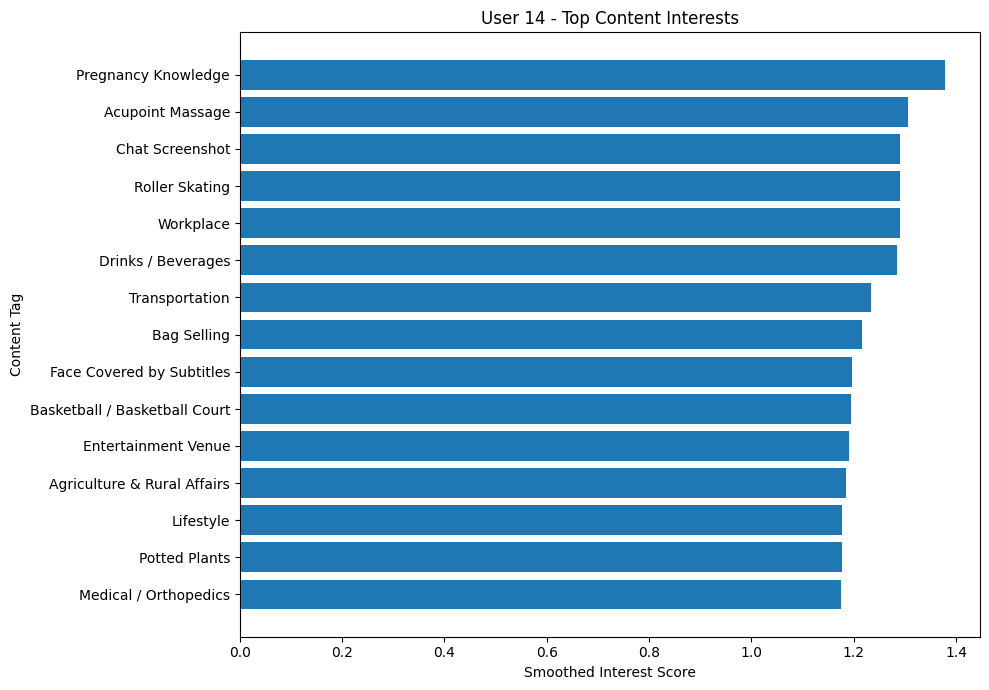

In [19]:
import matplotlib.pyplot as plt

top_interests = (
    user_interest
    .head(15)
    .sort_values("smoothed_interest")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_interests.index,
    top_interests["smoothed_interest"]
)

plt.xlabel("Smoothed Interest Score")
plt.ylabel("Content Tag")
plt.title("User 14 - Top Content Interests")

plt.tight_layout()
plt.show()

In [20]:
# Build smoothed interest profiles for all users

all_user_interest = (
    train_data
    .merge(
        video_tags[["video_id", "video_tag_en"]],
        on="video_id",
        how="left"
    )
    .dropna(subset=["video_tag_en"])
    .groupby(["user_id", "video_tag_en"])
    .agg(
        interactions=("video_id", "count"),
        avg_watch_score=("watch_score", "mean")
    )
    .reset_index()
)

# Calculate each user's overall average engagement
user_means = (
    train_data
    .groupby("user_id")["watch_score"]
    .mean()
    .rename("user_mean_watch_score")
    .reset_index()
)

# Add each user's overall mean
all_user_interest = all_user_interest.merge(
    user_means,
    on="user_id",
    how="left"
)

# Smoothing parameter
smoothing = 5

# Smoothed interest score
all_user_interest["smoothed_interest"] = (
    (
        all_user_interest["interactions"]
        * all_user_interest["avg_watch_score"]
        + smoothing * all_user_interest["user_mean_watch_score"]
    )
    /
    (
        all_user_interest["interactions"]
        + smoothing
    )
)

print("Users with interest profiles:", all_user_interest["user_id"].nunique())
print("Interest profile rows:", len(all_user_interest))
print("Unique content tags:", all_user_interest["video_tag_en"].nunique())

Users with interest profiles: 1411
Interest profile rows: 471361
Unique content tags: 341


In [21]:
# Identify tags that are present in the full dataset
# but not represented in the training-period interactions

training_tags = set(all_user_interest["video_tag_en"].unique())
all_tags_english = set(video_tags["video_tag_en"].dropna().unique())

tags_not_in_training = sorted(
    all_tags_english - training_tags
)

print("Tags in full interaction data:", len(all_tags_english))
print("Tags in training data:", len(training_tags))
print("Tags absent from training:", len(tags_not_in_training))

print("\nTags absent from training:")
for tag in tags_not_in_training:
    print("-", tag)

Tags in full interaction data: 341
Tags in training data: 341
Tags absent from training: 0

Tags absent from training:


In [22]:
# Rebuild all-user interest profiles while preserving
# the original KuaiRec tag distinctions

all_user_interest = (
    train_data
    .merge(
        video_tags[["video_id", "video_tag_name", "video_tag_en"]],
        on="video_id",
        how="left"
    )
    .dropna(subset=["video_tag_name"])
    .groupby(["user_id", "video_tag_name"])
    .agg(
        interactions=("video_id", "count"),
        avg_watch_score=("watch_score", "mean")
    )
    .reset_index()
)

# Add the English translation for presentation
all_user_interest["video_tag_en"] = (
    all_user_interest["video_tag_name"]
    .map(tag_translation)
)

# Calculate each user's overall average engagement
user_means = (
    train_data
    .groupby("user_id")["watch_score"]
    .mean()
    .rename("user_mean_watch_score")
    .reset_index()
)

all_user_interest = all_user_interest.merge(
    user_means,
    on="user_id",
    how="left"
)

# Smoothing parameter
smoothing = 5

# Smoothed interest score
all_user_interest["smoothed_interest"] = (
    (
        all_user_interest["interactions"]
        * all_user_interest["avg_watch_score"]
        + smoothing * all_user_interest["user_mean_watch_score"]
    )
    /
    (
        all_user_interest["interactions"]
        + smoothing
    )
)

print("Users with interest profiles:",
      all_user_interest["user_id"].nunique())

print("Interest profile rows:",
      len(all_user_interest))

print("Original tags represented:",
      all_user_interest["video_tag_name"].nunique())

print("English labels represented:",
      all_user_interest["video_tag_en"].nunique())

print("Missing English translations:",
      all_user_interest["video_tag_en"].isna().sum())

Users with interest profiles: 1411
Interest profile rows: 476973
Original tags represented: 345
English labels represented: 341
Missing English translations: 0


In [23]:
# Find original KuaiRec tags that do not appear in training

all_original_tags = set(
    video_tags["video_tag_name"].dropna().unique()
)

training_original_tags = set(
    all_user_interest["video_tag_name"].unique()
)

missing_training_tags = sorted(
    all_original_tags - training_original_tags
)

print("Original tags in full data:", len(all_original_tags))
print("Original tags in training:", len(training_original_tags))
print("Missing from training:", len(missing_training_tags))

print("\nMissing tag(s):")
for tag in missing_training_tags:
    print("-", tag)

Original tags in full data: 346
Original tags in training: 345
Missing from training: 1

Missing tag(s):
- 高档汽车


In [24]:
# Create a fast lookup table for user interest scores

interest_lookup = (
    all_user_interest[
        [
            "user_id",
            "video_tag_name",
            "video_tag_en",
            "smoothed_interest"
        ]
    ]
    .copy()
)

print("Interest lookup rows:", len(interest_lookup))
print("Users:", interest_lookup["user_id"].nunique())
print("Original tags:", interest_lookup["video_tag_name"].nunique())

Interest lookup rows: 476973
Users: 1411
Original tags: 345


In [25]:
# Create a clean video-tag table for relevance scoring

video_tag_lookup = (
    video_tags[
        ["video_id", "video_tag_name", "video_tag_en"]
    ]
    .drop_duplicates("video_id")
    .copy()
)

print("Videos with tags:", len(video_tag_lookup))
print("Unique videos:", video_tag_lookup["video_id"].nunique())
print("Unique original tags:",
      video_tag_lookup["video_tag_name"].nunique())

Videos with tags: 3324
Unique videos: 3324
Unique original tags: 346


In [26]:
# Create user-video interest relevance scores

user_video_interest = (
    video_tag_lookup
    .merge(
        interest_lookup[
            [
                "user_id",
                "video_tag_name",
                "smoothed_interest"
            ]
        ],
        on="video_tag_name",
        how="inner"
    )
)

# Rename for clarity
user_video_interest = user_video_interest.rename(
    columns={
        "smoothed_interest": "interest_relevance"
    }
)

print("User-video relevance rows:", len(user_video_interest))
print("Users represented:", user_video_interest["user_id"].nunique())
print("Videos represented:", user_video_interest["video_id"].nunique())

display(user_video_interest.head(10))

User-video relevance rows: 4678474
Users represented: 1411
Videos represented: 3323


,video_id,video_tag_name,video_tag_en,user_id,interest_relevance
0,103,面食,Noodles & Flour-Based Foods,14,0.678078
1,103,面食,Noodles & Flour-Based Foods,19,0.620451
2,103,面食,Noodles & Flour-Based Foods,21,0.822872
3,103,面食,Noodles & Flour-Based Foods,23,0.641184
4,103,面食,Noodles & Flour-Based Foods,24,0.585207
5,103,面食,Noodles & Flour-Based Foods,36,0.589549
6,103,面食,Noodles & Flour-Based Foods,37,0.676746
7,103,面食,Noodles & Flour-Based Foods,41,0.617300
8,103,面食,Noodles & Flour-Based Foods,51,0.703009
9,103,面食,Noodles & Flour-Based Foods,55,0.532441


In [27]:
# Create all user-video combinations for tagged videos

users = train_data["user_id"].unique()
videos = video_tag_lookup["video_id"].unique()

user_video_pairs = pd.MultiIndex.from_product(
    [users, videos],
    names=["user_id", "video_id"]
).to_frame(index=False)

print("Total user-video pairs:", len(user_video_pairs))
print("Users:", user_video_pairs["user_id"].nunique())
print("Videos:", user_video_pairs["video_id"].nunique())

Total user-video pairs: 4690164
Users: 1411
Videos: 3324


In [28]:
# Attach each video's original and English tag to every user-video pair

user_video_candidates = user_video_pairs.merge(
    video_tag_lookup,
    on="video_id",
    how="left"
)

print("Candidate rows:", len(user_video_candidates))
print("Missing video tags:",
      user_video_candidates["video_tag_name"].isna().sum())

display(user_video_candidates.head(10))

Candidate rows: 4690164
Missing video tags: 0


,user_id,video_id,video_tag_name,video_tag_en
0,14,103,面食,Noodles & Flour-Based Foods
1,14,109,摩托车,Motorcycle
2,14,120,搞笑,Comedy / Funny
3,14,122,猴,Monkey
4,14,128,美食,Food
5,14,130,侧面,Side View
6,14,131,电影黑条,Movie Black Bars
7,14,133,猫,Cat
8,14,136,人群聚集,Crowd Gathering
9,14,137,影视介绍,Film & TV Introduction


In [29]:
# Attach each user's learned interest score to each candidate video

user_video_candidates = user_video_candidates.merge(
    interest_lookup[
        [
            "user_id",
            "video_tag_name",
            "smoothed_interest"
        ]
    ],
    on=["user_id", "video_tag_name"],
    how="left"
)

# Videos whose tag is not represented in a user's history
# receive zero interest evidence
user_video_candidates["interest_relevance"] = (
    user_video_candidates["smoothed_interest"]
    .fillna(0)
)

print(
    "Candidate rows:",
    len(user_video_candidates)
)

print(
    "Non-zero interest scores:",
    (
        user_video_candidates["interest_relevance"] > 0
    ).sum()
)

print(
    "Zero interest scores:",
    (
        user_video_candidates["interest_relevance"] == 0
    ).sum()
)

display(
    user_video_candidates.head(10)
)

Candidate rows: 4690164
Non-zero interest scores: 4678474
Zero interest scores: 11690


,user_id,video_id,video_tag_name,video_tag_en,smoothed_interest,interest_relevance
0,14,103,面食,Noodles & Flour-Based Foods,0.678078,0.678078
1,14,109,摩托车,Motorcycle,0.972070,0.972070
2,14,120,搞笑,Comedy / Funny,1.075264,1.075264
3,14,122,猴,Monkey,0.788069,0.788069
4,14,128,美食,Food,1.018623,1.018623
5,14,130,侧面,Side View,0.997995,0.997995
6,14,131,电影黑条,Movie Black Bars,1.054189,1.054189
7,14,133,猫,Cat,1.108887,1.108887
8,14,136,人群聚集,Crowd Gathering,0.791124,0.791124
9,14,137,影视介绍,Film & TV Introduction,1.164224,1.164224


In [30]:
# Inspect the distribution of the interest relevance score

interest_stats = (
    user_video_candidates["interest_relevance"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

display(interest_stats)

count    4.690164e+06
mean     8.613609e-01
std      1.971391e-01
min      0.000000e+00
25%      7.419665e-01
50%      8.528570e-01
75%      9.775233e-01
90%      1.108475e+00
95%      1.193928e+00
99%      1.371540e+00
max      2.022816e+00
Name: interest_relevance, dtype: float64

In [31]:
# Normalize interest relevance within each user
# so that each user's strongest interests receive higher relative scores.

user_video_candidates["interest_relevance_norm"] = (
    user_video_candidates
    .groupby("user_id")["interest_relevance"]
    .transform(
        lambda x: (
            (x - x.min()) /
            (x.max() - x.min())
            if x.max() > x.min()
            else 0
        )
    )
)

print(
    "Normalized score range:",
    user_video_candidates["interest_relevance_norm"].min(),
    "to",
    user_video_candidates["interest_relevance_norm"].max()
)

display(
    user_video_candidates[
        [
            "user_id",
            "video_id",
            "video_tag_en",
            "interest_relevance",
            "interest_relevance_norm"
        ]
    ].head(10)
)

Normalized score range: 0.0 to 1.0


,user_id,video_id,video_tag_en,interest_relevance,interest_relevance_norm
0,14,103,Noodles & Flour-Based Foods,0.678078,0.492049
1,14,109,Motorcycle,0.972070,0.705385
2,14,120,Comedy / Funny,1.075264,0.780268
3,14,122,Monkey,0.788069,0.571864
4,14,128,Food,1.018623,0.739166
5,14,130,Side View,0.997995,0.724198
6,14,131,Movie Black Bars,1.054189,0.764975
7,14,133,Cat,1.108887,0.804667
8,14,136,Crowd Gathering,0.791124,0.574081
9,14,137,Film & TV Introduction,1.164224,0.844822


In [32]:
# Top interests for User 14 after normalization

user_14_interests = (
    user_video_candidates[
        user_video_candidates["user_id"] == 14
    ][
        [
            "video_tag_name",
            "video_tag_en",
            "interest_relevance",
            "interest_relevance_norm"
        ]
    ]
    .drop_duplicates("video_tag_name")
    .sort_values(
        "interest_relevance_norm",
        ascending=False
    )
)

display(user_14_interests.head(20))

,video_tag_name,video_tag_en,interest_relevance,interest_relevance_norm
710,孕妇知识,Pregnancy Knowledge,1.378070,1.000000
2622,穴位按摩,Acupoint Massage,1.306115,0.947786
1783,聊天截屏,Chat Screenshot,1.290261,0.936281
3197,工作场所,Workplace,1.290261,0.936281
534,轮滑,Roller Skating,1.290261,0.936281
30,饮料,Drinks / Beverages,1.285701,0.932972
2505,猴子,Monkey,1.259749,0.914140
741,交通工具,Transportation,1.234349,0.895709
204,卖包,Bag Selling,1.216776,0.882956
222,字幕遮脸,Face Covered by Subtitles,1.196196,0.868023


In [33]:
# Inspect User 14's interests with interaction frequency

user_14_interest_detail = (
    all_user_interest[
        all_user_interest["user_id"] == 14
    ][
        [
            "video_tag_name",
            "video_tag_en",
            "interactions",
            "avg_watch_score",
            "smoothed_interest"
        ]
    ]
    .copy()
)

# Add the normalized score
user_14_interest_detail = user_14_interest_detail.merge(
    user_14_interests[
        [
            "video_tag_name",
            "interest_relevance_norm"
        ]
    ],
    on="video_tag_name",
    how="left"
)

user_14_interest_detail = (
    user_14_interest_detail
    .sort_values(
        "interest_relevance_norm",
        ascending=False
    )
)

display(user_14_interest_detail.head(20))

,video_tag_name,video_tag_en,interactions,avg_watch_score,smoothed_interest,interest_relevance_norm
97,孕妇知识,Pregnancy Knowledge,3,2.094331,1.378070,1.000000
236,穴位按摩,Acupoint Massage,3,1.902452,1.306115,0.947786
114,工作场所,Workplace,1,3.000000,1.290261,0.936281
255,聊天截屏,Chat Screenshot,1,3.000000,1.290261,0.936281
295,轮滑,Roller Skating,1,3.000000,1.290261,0.936281
324,饮料,Drinks / Beverages,3,1.848015,1.285701,0.932972
208,猴子,Monkey,2,2.038340,1.259749,0.914140
12,交通工具,Transportation,2,1.949438,1.234349,0.895709
47,卖包,Bag Selling,1,2.559088,1.216776,0.882956
98,字幕遮脸,Face Covered by Subtitles,3,1.609334,1.196196,0.868023


In [34]:
# Distribution of interaction counts across User 14's content interests

interaction_count_stats = (
    user_14_interest_detail["interactions"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

display(interaction_count_stats)

count    340.000000
mean       9.279412
std       23.329906
min        1.000000
25%        1.000000
50%        3.000000
75%        7.000000
90%       23.000000
95%       45.050000
max      314.000000
Name: interactions, dtype: float64

In [35]:
# Examine engagement strength at different interaction-frequency levels

user_14_interest_detail["frequency_group"] = pd.cut(
    user_14_interest_detail["interactions"],
    bins=[0, 1, 3, 7, 20, np.inf],
    labels=[
        "1 interaction",
        "2–3 interactions",
        "4–7 interactions",
        "8–20 interactions",
        "21+ interactions"
    ]
)

frequency_analysis = (
    user_14_interest_detail
    .groupby("frequency_group", observed=False)
    .agg(
        number_of_tags=("video_tag_name", "count"),
        average_interactions=("interactions", "mean"),
        average_watch_score=("avg_watch_score", "mean"),
        average_smoothed_interest=("smoothed_interest", "mean")
    )
    .reset_index()
)

display(frequency_analysis)

,frequency_group,number_of_tags,average_interactions,average_watch_score,average_smoothed_interest
0,1 interaction,104,1.000000,0.896101,0.939611
1,2–3 interactions,96,2.395833,0.966426,0.958834
2,4–7 interactions,57,5.052632,0.897881,0.920101
3,8–20 interactions,47,12.234043,0.924933,0.930920
4,21+ interactions,36,54.388889,0.958606,0.956892


In [36]:
# Create the interest-aware candidate set for User 14
# Remove videos already watched during training.

target_user_id = 14

user_14_watched = set(
    train_data.loc[
        train_data["user_id"] == target_user_id,
        "video_id"
    ]
)

user_14_candidates = (
    user_video_candidates[
        user_video_candidates["user_id"] == target_user_id
    ]
    .copy()
)

user_14_candidates = user_14_candidates[
    ~user_14_candidates["video_id"].isin(user_14_watched)
].copy()

print("User 14 training videos watched:", len(user_14_watched))
print("Candidate videos before filtering:", 3324)
print("Candidate videos after removing watched videos:",
      len(user_14_candidates))

User 14 training videos watched: 3158
Candidate videos before filtering: 3324
Candidate videos after removing watched videos: 169


In [37]:
# Generate User 14's top interest-aware recommendations

interest_recommendations_14 = (
    user_14_candidates
    .sort_values(
        "interest_relevance_norm",
        ascending=False
    )
    .head(10)
    .copy()
)

display(
    interest_recommendations_14[
        [
            "video_id",
            "video_tag_name",
            "video_tag_en",
            "interest_relevance",
            "interest_relevance_norm"
        ]
    ]
)

,video_id,video_tag_name,video_tag_en,interest_relevance,interest_relevance_norm
2102,6177,生活,Lifestyle,1.177024,0.854110
2262,7003,生活,Lifestyle,1.177024,0.854110
2972,9167,生活,Lifestyle,1.177024,0.854110
1716,5027,生活,Lifestyle,1.177024,0.854110
2792,8624,医疗_骨科,Medical / Orthopedics,1.174959,0.852612
2166,6296,狗,Dog,1.170326,0.849250
3182,9989,狗,Dog,1.170326,0.849250
1156,3117,体育运动,Sports,1.164688,0.845159
1551,4358,卖鞋,Shoe Sales,1.149762,0.834327
1510,4222,卖鞋,Shoe Sales,1.149762,0.834327


In [39]:
# Recreate the collaborative-filtering baseline for User 14
# using the same training data as Notebook 02.

from sklearn.metrics.pairwise import cosine_similarity

# Create user-video interaction matrix from training data
user_video_matrix = (
    train_data
    .pivot_table(
        index="user_id",
        columns="video_id",
        values="watch_score",
        aggfunc="mean",
        fill_value=0
    )
)

# Compute user-user similarity
user_similarity = cosine_similarity(user_video_matrix)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_video_matrix.index,
    columns=user_video_matrix.index
)

# Get similar users for User 14
similar_users = (
    user_similarity_df.loc[target_user_id]
    .drop(target_user_id)
    .sort_values(ascending=False)
)

top_similar_users = similar_users.head(20).index

print("Top similar users for User 14:")
print(top_similar_users.tolist())


Top similar users for User 14:
[1584, 1641, 4819, 3948, 1704, 3223, 840, 2143, 6927, 2118, 5297, 4239, 5191, 4955, 5888, 6099, 3404, 2131, 6518, 3825]


In [40]:
# Generate the collaborative-filtering baseline recommendations for User 14

# Average watch score of the top similar users for each video
similar_user_scores = (
    user_video_matrix.loc[top_similar_users]
    .mean(axis=0)
)

# Videos already watched by User 14 during training
watched_videos = set(
    train_data.loc[
        train_data["user_id"] == target_user_id,
        "video_id"
    ]
)

# Remove videos User 14 has already watched
baseline_14 = (
    similar_user_scores
    .drop(labels=list(watched_videos), errors="ignore")
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

baseline_14.columns = [
    "video_id",
    "baseline_score"
]

display(baseline_14)

,video_id,baseline_score
0,3107,1.464174
1,152,1.245391
2,3992,1.194046
3,2065,1.165584
4,6177,1.157358
5,6086,1.117231
6,10046,1.089828
7,835,1.082791
8,6308,1.078557
9,7263,1.070285


In [41]:
# Compare baseline and interest-aware recommendations

baseline_video_ids = set(
    baseline_14["video_id"]
)

interest_video_ids = set(
    interest_recommendations_14["video_id"]
)

overlap = baseline_video_ids.intersection(
    interest_video_ids
)

print("Baseline recommendations:", len(baseline_video_ids))
print("Interest-aware recommendations:", len(interest_video_ids))
print("Overlapping videos:", len(overlap))
print("Overlap rate:", len(overlap) / 10)

print("\nOverlapping video IDs:")
print(sorted(overlap))

Baseline recommendations: 10
Interest-aware recommendations: 10
Overlapping videos: 1
Overlap rate: 0.1

Overlapping video IDs:
[6177]


In [42]:
# Evaluate User 14's interest-aware Top-10 recommendations
# against their held-out test interactions.

user_14_test_videos = set(
    test_data.loc[
        test_data["user_id"] == target_user_id,
        "video_id"
    ]
)

interest_hits = (
    interest_video_ids.intersection(
        user_14_test_videos
    )
)

print("User 14 test videos:", len(user_14_test_videos))
print("Interest-aware Top-10:", len(interest_video_ids))
print("Interest-aware hits:", len(interest_hits))
print("Interest-aware HitRate@10:", len(interest_hits) / 10)

print("\nHit video IDs:")
print(sorted(interest_hits))

User 14 test videos: 76
Interest-aware Top-10: 10
Interest-aware hits: 5
Interest-aware HitRate@10: 0.5

Hit video IDs:
[3117, 4222, 5027, 6296, 8624]


In [43]:
# Generate interest-aware Top-10 recommendations for all users

all_interest_recommendations = (
    user_video_candidates[
        ~user_video_candidates.set_index(
            ["user_id", "video_id"]
        ).index.isin(
            train_data.set_index(
                ["user_id", "video_id"]
            ).index
        )
    ]
    .sort_values(
        ["user_id", "interest_relevance_norm"],
        ascending=[True, False]
    )
    .groupby("user_id")
    .head(10)
    .reset_index(drop=True)
)

print(
    "Users with recommendations:",
    all_interest_recommendations["user_id"].nunique()
)

print(
    "Total recommendation slots:",
    len(all_interest_recommendations)
)

print(
    "Average recommendations per user:",
    len(all_interest_recommendations)
    / all_interest_recommendations["user_id"].nunique()
)

display(
    all_interest_recommendations.head(10)
)

Users with recommendations: 1411
Total recommendation slots: 14110
Average recommendations per user: 10.0


,user_id,video_id,video_tag_name,video_tag_en,smoothed_interest,interest_relevance,interest_relevance_norm
0,14,5027,生活,Lifestyle,1.177024,1.177024,0.854110
1,14,6177,生活,Lifestyle,1.177024,1.177024,0.854110
2,14,7003,生活,Lifestyle,1.177024,1.177024,0.854110
3,14,9167,生活,Lifestyle,1.177024,1.177024,0.854110
4,14,8624,医疗_骨科,Medical / Orthopedics,1.174959,1.174959,0.852612
5,14,6296,狗,Dog,1.170326,1.170326,0.849250
6,14,9989,狗,Dog,1.170326,1.170326,0.849250
7,14,3117,体育运动,Sports,1.164688,1.164688,0.845159
8,14,4222,卖鞋,Shoe Sales,1.149762,1.149762,0.834327
9,14,4358,卖鞋,Shoe Sales,1.149762,1.149762,0.834327


In [44]:
# Evaluate Interest-Aware recommendations for all users

# Create a lookup of test videos for each user
test_videos_by_user = (
    test_data
    .groupby("user_id")["video_id"]
    .apply(set)
)

# Calculate hits for each user
interest_user_results = []

for user_id, group in all_interest_recommendations.groupby("user_id"):
    
    recommended_videos = set(group["video_id"])
    
    actual_test_videos = test_videos_by_user.get(
        user_id,
        set()
    )
    
    hits = recommended_videos.intersection(
        actual_test_videos
    )
    
    interest_user_results.append({
        "user_id": user_id,
        "hits": len(hits),
        "hit_rate_at_10": len(hits) / 10
    })

interest_user_results = pd.DataFrame(
    interest_user_results
)

print(
    "Users evaluated:",
    len(interest_user_results)
)

print(
    "Average HitRate@10:",
    interest_user_results["hit_rate_at_10"].mean()
)

print(
    "Users with at least one hit:",
    (interest_user_results["hits"] > 0).sum()
)

print(
    "Percentage of users with at least one hit:",
    (interest_user_results["hits"] > 0).mean() * 100
)

display(
    interest_user_results["hit_rate_at_10"].describe()
)

Users evaluated: 1411
Average HitRate@10: 0.43876683203401834
Users with at least one hit: 1396
Percentage of users with at least one hit: 98.93692416725727


count    1411.000000
mean        0.438767
std         0.221327
min         0.000000
25%         0.300000
50%         0.400000
75%         0.600000
max         1.000000
Name: hit_rate_at_10, dtype: float64

In [45]:
# Measure content-tag diversity in interest-aware recommendations

interest_tag_diversity = (
    all_interest_recommendations
    .groupby("user_id")["video_tag_name"]
    .nunique()
)

print(
    "Average unique tags per user's Top-10:",
    interest_tag_diversity.mean()
)

print(
    "Median unique tags per user's Top-10:",
    interest_tag_diversity.median()
)

print(
    "Minimum unique tags:",
    interest_tag_diversity.min()
)

print(
    "Maximum unique tags:",
    interest_tag_diversity.max()
)

display(
    interest_tag_diversity.describe()
)

Average unique tags per user's Top-10: 5.309000708717222
Median unique tags per user's Top-10: 5.0
Minimum unique tags: 1
Maximum unique tags: 10


count    1411.000000
mean        5.309001
std         1.867846
min         1.000000
25%         4.000000
50%         5.000000
75%         7.000000
max        10.000000
Name: video_tag_name, dtype: float64

In [1]:
# Cell 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import ast

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Cell 2: Define data paths

processed_path = "../processed_data"
results_path = "../results"

print("Processed data directory:", os.path.abspath(processed_path))
print("Results directory:", os.path.abspath(results_path))

print("\nAvailable processed files:")

for file in os.listdir(processed_path):
    print("-", file)

Processed data directory: c:\Users\Shrutee Patil\Desktop\MSC Part 2 Sem 3\Research Project\Spotlight_project\processed_data
Results directory: c:\Users\Shrutee Patil\Desktop\MSC Part 2 Sem 3\Research Project\Spotlight_project\results

Available processed files:
- category_distribution.csv
- creator_popularity.csv
- interactions.csv
- testing_interactions.csv
- training_interactions.csv
- video_creator_groups.csv
- video_creator_map.csv
- video_metadata.csv


In [3]:
# Cell 3: Load datasets for interest modeling

training_data = pd.read_csv(
    os.path.join(processed_path, "training_interactions.csv")
)

video_metadata = pd.read_csv(
    os.path.join(processed_path, "video_metadata.csv")
)

print("Training data shape:", training_data.shape)
print("Video metadata shape:", video_metadata.shape)

print("\nTraining data columns:")
print(training_data.columns.tolist())

print("\nVideo metadata columns:")
print(video_metadata.columns.tolist())

Training data shape: (4387382, 9)
Video metadata shape: (3327, 12)

Training data columns:
['user_id', 'video_id', 'play_duration', 'video_duration', 'time', 'date', 'timestamp', 'watch_ratio', 'interaction_date']

Video metadata columns:
['video_id', 'category_ids', 'category_count', 'manual_cover_text', 'caption', 'topic_tag', 'first_level_category_id', 'first_level_category_name', 'second_level_category_id', 'second_level_category_name', 'third_level_category_id', 'third_level_category_name']


In [4]:
# Cell 4: Inspect video category representation

print("Category IDs data type:")
print(video_metadata["category_ids"].dtype)

print("\nSample category values:")
display(
    video_metadata[
        ["video_id", "category_ids", "category_count"]
    ].head(15)
)

print("\nCategory count distribution:")
print(video_metadata["category_count"].value_counts().sort_index())

Category IDs data type:
object

Sample category values:


,video_id,category_ids,category_count
0,103,[12],1
1,109,"[18, 5]",2
2,120,[9],1
3,122,[9],1
4,128,"[11, 12, 9]",3
5,130,"[15, 20]",2
6,131,"[9, 28]",2
7,133,[17],1
8,136,"[11, 28]",2
9,137,[28],1



Category count distribution:
category_count
1    2209
2     973
3     138
4       7
Name: count, dtype: int64


In [5]:
# Cell 5: Parse category IDs

video_metadata["category_ids"] = video_metadata["category_ids"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

print("Category IDs parsed successfully!")

print("\nSample parsed categories:")
display(
    video_metadata[
        ["video_id", "category_ids", "category_count"]
    ].head(10)
)

print("\nData type after parsing:")
print(type(video_metadata["category_ids"].iloc[0]))

Category IDs parsed successfully!

Sample parsed categories:


,video_id,category_ids,category_count
0,103,[12],1
1,109,"[18, 5]",2
2,120,[9],1
3,122,[9],1
4,128,"[11, 12, 9]",3
5,130,"[15, 20]",2
6,131,"[9, 28]",2
7,133,[17],1
8,136,"[11, 28]",2
9,137,[28],1



Data type after parsing:
<class 'list'>


In [6]:
# Cell 6: Validate category metadata

# Check whether every category_ids entry is a list
all_lists = video_metadata["category_ids"].apply(lambda x: isinstance(x, list)).all()

# Check for empty category lists
empty_categories = video_metadata["category_ids"].apply(lambda x: len(x) == 0).sum()

# Check whether category IDs are numerical
valid_category_ids = video_metadata["category_ids"].apply(
    lambda x: all(isinstance(cat, (int, float)) for cat in x)
).all()

# Check consistency between category_count and actual list length
count_mismatches = (
    video_metadata["category_count"] !=
    video_metadata["category_ids"].apply(len)
).sum()

print("All category entries are lists:", all_lists)
print("Videos with empty category lists:", empty_categories)
print("All category IDs are numerical:", valid_category_ids)
print("Category count mismatches:", count_mismatches)

All category entries are lists: True
Videos with empty category lists: 0
All category IDs are numerical: True
Category count mismatches: 0


In [7]:
# Cell 7: Analyse category distribution

# Expand multi-label categories into individual rows
exploded_categories = video_metadata[["video_id", "category_ids"]].explode("category_ids")

# Calculate the number of videos associated with each category
category_video_counts = (
    exploded_categories.groupby("category_ids")["video_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
)

category_video_counts.columns = ["category_id", "video_count"]

# Calculate percentage of videos assigned to each category
category_video_counts["percentage"] = (
    category_video_counts["video_count"] / len(video_metadata) * 100
)

print("Number of unique categories:", category_video_counts["category_id"].nunique())
print("\nCategory distribution:")
display(category_video_counts)

Number of unique categories: 31

Category distribution:


,category_id,video_count,percentage
0,28,849,25.518485
1,8,506,15.208897
2,6,451,13.555756
3,11,426,12.804328
4,9,332,9.978960
5,26,330,9.918846
6,7,208,6.251879
7,17,189,5.680794
8,1,163,4.899309
9,25,161,4.839194


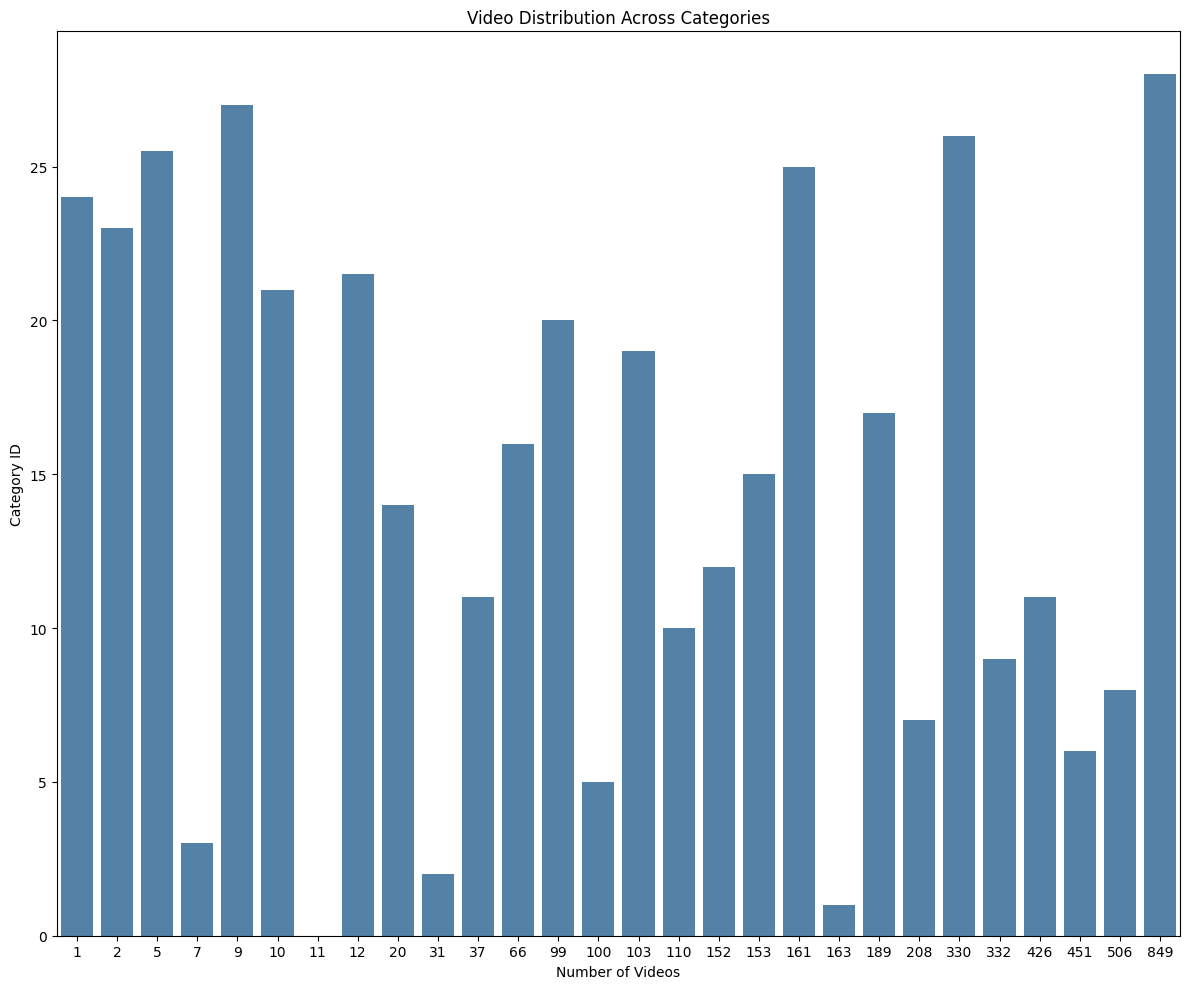

In [9]:
# Cell 8: Visualise category distribution

plt.figure(figsize=(12, 10))

sns.barplot(
    data=category_video_counts,
    x="video_count",
    y="category_id",
    color="steelblue",
    errorbar=None
)

plt.title("Video Distribution Across Categories")
plt.xlabel("Number of Videos")
plt.ylabel("Category ID")
plt.tight_layout()
plt.show()

In [10]:
# Cell 9: Prepare training interactions for interest modelling

interest_interactions = training_data[
    ["user_id", "video_id", "watch_ratio"]
].copy()

# Cap watch ratio between 0 and 1
interest_interactions["preference_score"] = (
    interest_interactions["watch_ratio"].clip(0, 1)
)

print("Interest interaction dataset shape:", interest_interactions.shape)
print("\nSample:")
display(interest_interactions.head())

print("\nPreference score statistics:")
display(interest_interactions["preference_score"].describe())

Interest interaction dataset shape: (4387382, 4)

Sample:


,user_id,video_id,watch_ratio,preference_score
0,14,148,0.722103,0.722103
1,14,183,1.907377,1.000000
2,14,3649,2.063311,1.000000
3,14,5262,0.566388,0.566388
4,14,8234,0.418364,0.418364



Preference score statistics:


count    4.387382e+06
mean     6.995833e-01
std      3.075442e-01
min      0.000000e+00
25%      4.735927e-01
50%      7.742437e-01
75%      1.000000e+00
max      1.000000e+00
Name: preference_score, dtype: float64

In [11]:
# Cell 10: Merge interaction data with video category metadata

interest_data = interest_interactions.merge(
    video_metadata[["video_id", "category_ids", "category_count"]],
    on="video_id",
    how="left",
    validate="many_to_one"
)

print("Merged interest dataset shape:", interest_data.shape)

# Check missing category metadata
missing_categories = interest_data["category_ids"].isna().sum()

print("Interactions missing category metadata:", missing_categories)
print("Percentage missing:", round(missing_categories / len(interest_data) * 100, 4), "%")

print("\nSample merged data:")
display(interest_data.head())

Merged interest dataset shape: (4387382, 6)
Interactions missing category metadata: 0
Percentage missing: 0.0 %

Sample merged data:


,user_id,video_id,watch_ratio,preference_score,category_ids,category_count
0,14,148,0.722103,0.722103,"[11, 28, 19]",3
1,14,183,1.907377,1.000000,[28],1
2,14,3649,2.063311,1.000000,[9],1
3,14,5262,0.566388,0.566388,[25],1
4,14,8234,0.418364,0.418364,[6],1


In [12]:
# Cell 11: Distribute preference scores across video categories

# Expand each video into separate category rows
user_category_interactions = interest_data.explode("category_ids").copy()

# Allocate preference equally across all assigned categories
user_category_interactions["category_contribution"] = (
    user_category_interactions["preference_score"] /
    user_category_interactions["category_count"]
)

print("Expanded dataset shape:", user_category_interactions.shape)

print("\nSample category-level interactions:")
display(
    user_category_interactions[
        ["user_id", "video_id", "category_ids",
         "preference_score", "category_count", "category_contribution"]
    ].head(10)
)

Expanded dataset shape: (6063117, 7)

Sample category-level interactions:


,user_id,video_id,category_ids,preference_score,category_count,category_contribution
0,14,148,11,0.722103,3,0.240701
0,14,148,28,0.722103,3,0.240701
0,14,148,19,0.722103,3,0.240701
1,14,183,28,1.000000,1,1.000000
2,14,3649,9,1.000000,1,1.000000
3,14,5262,25,0.566388,1,0.566388
4,14,8234,6,0.418364,1,0.418364
5,14,6789,1,0.648753,1,0.648753
6,14,1963,9,0.898123,2,0.449062
6,14,1963,28,0.898123,2,0.449062


In [13]:
# Cell 12: Aggregate user-category interest

user_category_interest = (
    user_category_interactions
    .groupby(["user_id", "category_ids"])["category_contribution"]
    .sum()
    .reset_index()
)

user_category_interest.rename(
    columns={
        "category_ids": "category_id",
        "category_contribution": "interest_score"
    },
    inplace=True
)

print("User-category interest dataset shape:", user_category_interest.shape)

print("\nSample user-category interest scores:")
display(user_category_interest.head(15))

User-category interest dataset shape: (43707, 3)

Sample user-category interest scores:


,user_id,category_id,interest_score
0,14,0,3.714641
1,14,1,87.236019
2,14,2,11.490888
3,14,3,1.635982
4,14,4,20.575255
5,14,5,50.118058
6,14,6,219.677215
7,14,7,138.418552
8,14,8,259.857319
9,14,9,131.379608


In [14]:
# Cell 13: Normalize user-category interest scores

user_category_interest["interest_weight"] = (
    user_category_interest["interest_score"] /
    user_category_interest.groupby("user_id")["interest_score"].transform("sum")
)

print("Normalized user-category profiles created!")

# Verify profile sums
profile_sums = (
    user_category_interest.groupby("user_id")["interest_weight"].sum()
)

print("\nProfile sum statistics:")
display(profile_sums.describe())

print("\nNumber of users:", profile_sums.shape[0])
print("Profiles not summing to 1:", 
      ((profile_sums - 1).abs() > 1e-6).sum())

print("\nSample normalized profile for User 14:")
display(
    user_category_interest[
        user_category_interest["user_id"] == 14
    ].sort_values("interest_weight", ascending=False)
)

Normalized user-category profiles created!

Profile sum statistics:


count    1.411000e+03
mean     1.000000e+00
std      5.687240e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: interest_weight, dtype: float64


Number of users: 1411
Profiles not summing to 1: 0

Sample normalized profile for User 14:


,user_id,category_id,interest_score,interest_weight
28,14,28,507.978342,0.218828
8,14,8,259.857319,0.111942
6,14,6,219.677215,0.094633
11,14,11,191.827600,0.082636
26,14,26,146.794535,0.063237
7,14,7,138.418552,0.059628
9,14,9,131.379608,0.056596
17,14,17,111.912526,0.048210
1,14,1,87.236019,0.037580
15,14,15,85.435851,0.036804


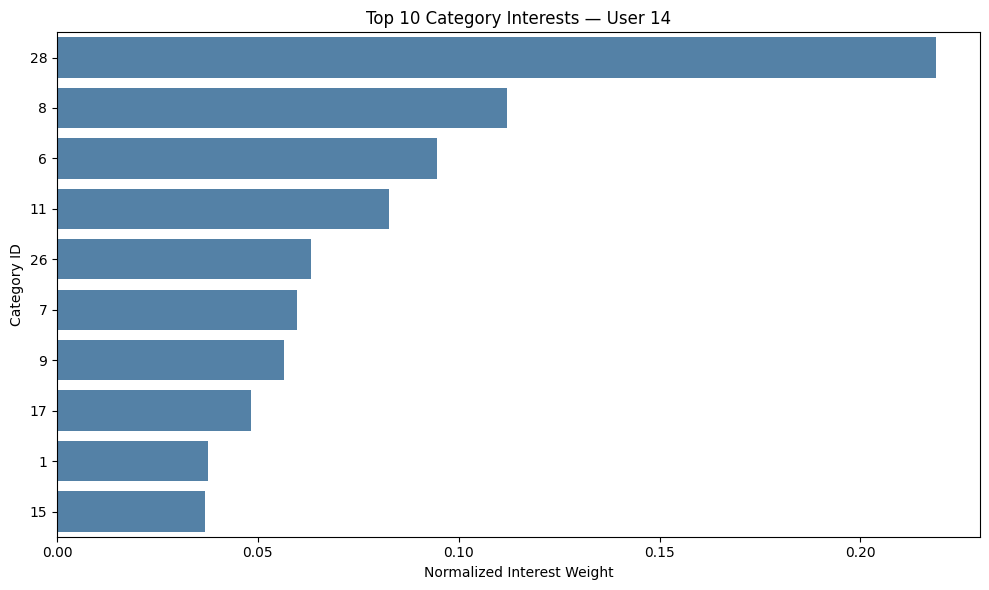

In [16]:
# Cell 14: Visualise an individual user interest profile

sample_user_id = 14

sample_profile = (
    user_category_interest[
        user_category_interest["user_id"] == sample_user_id
    ]
    .sort_values("interest_weight", ascending=False)
    .head(10)
    .copy()
)

# Convert category IDs to categorical labels for plotting
sample_profile["category_id"] = sample_profile["category_id"].astype(str)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=sample_profile,
    x="interest_weight",
    y="category_id",
    orient="h",
    color="steelblue",
    errorbar=None
)

plt.title(f"Top 10 Category Interests — User {sample_user_id}")
plt.xlabel("Normalized Interest Weight")
plt.ylabel("Category ID")
plt.tight_layout()
plt.show()

In [17]:
# Cell 15: Analyse interest profiles across the user population

# Number of categories represented in each user's profile
user_category_counts = (
    user_category_interest.groupby("user_id")["category_id"]
    .nunique()
)

# Average normalized interest assigned to each category across users
category_average_interest = (
    user_category_interest.groupby("category_id")["interest_weight"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

print("User category profile statistics:")
display(user_category_counts.describe())

print("\nAverage number of categories per user:", 
      round(user_category_counts.mean(), 2))

print("\nCategory average interest across users:")
display(category_average_interest)

print("\nTotal users analysed:", user_category_counts.nunique() * 0 + user_category_counts.shape[0])

User category profile statistics:


count    1411.000000
mean       30.975904
std         0.153403
min        30.000000
25%        31.000000
50%        31.000000
75%        31.000000
max        31.000000
Name: category_id, dtype: float64


Average number of categories per user: 30.98

Category average interest across users:


,category_id,interest_weight
0,28,0.218294
1,8,0.113804
2,6,0.091596
3,11,0.082883
4,26,0.065624
5,7,0.060467
6,9,0.054629
7,17,0.047251
8,15,0.038196
9,1,0.037994



Total users analysed: 1411


In [18]:
# Cell 16: Measure interest concentration across users

def calculate_profile_metrics(profile):
    weights = profile["interest_weight"].values

    # Top 3 category interest share
    top_3_share = np.sort(weights)[-3:].sum()

    # Shannon entropy
    entropy = -np.sum(weights * np.log(weights + 1e-12))

    # Effective number of categories
    effective_categories = np.exp(entropy)

    return pd.Series({
        "top_3_interest_share": top_3_share,
        "interest_entropy": entropy,
        "effective_categories": effective_categories
    })


user_interest_metrics = (
    user_category_interest
    .groupby("user_id")
    .apply(calculate_profile_metrics)
    .reset_index()
)

print("User interest concentration metrics:")
display(user_interest_metrics.head())

print("\nSummary statistics:")
display(user_interest_metrics.drop(columns="user_id").describe())

User interest concentration metrics:


C:\Users\Shrutee Patil\AppData\Local\Temp\ipykernel_7100\1422745158.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_profile_metrics)


,user_id,top_3_interest_share,interest_entropy,effective_categories
0,14,0.425404,2.682197,14.617169
1,19,0.422860,2.679368,14.575873
2,21,0.416175,2.694675,14.800711
3,23,0.415169,2.685570,14.666565
4,24,0.428517,2.676274,14.530855



Summary statistics:


,top_3_interest_share,interest_entropy,effective_categories
count,1411.000000,1411.000000,1411.000000
mean,0.423762,2.683327,14.634599
std,0.005279,0.011131,0.162973
min,0.402385,2.647527,14.119080
25%,0.420287,2.675695,14.522435
50%,0.423962,2.683542,14.636852
75%,0.427096,2.690440,14.738155
max,0.441994,2.725150,15.258703


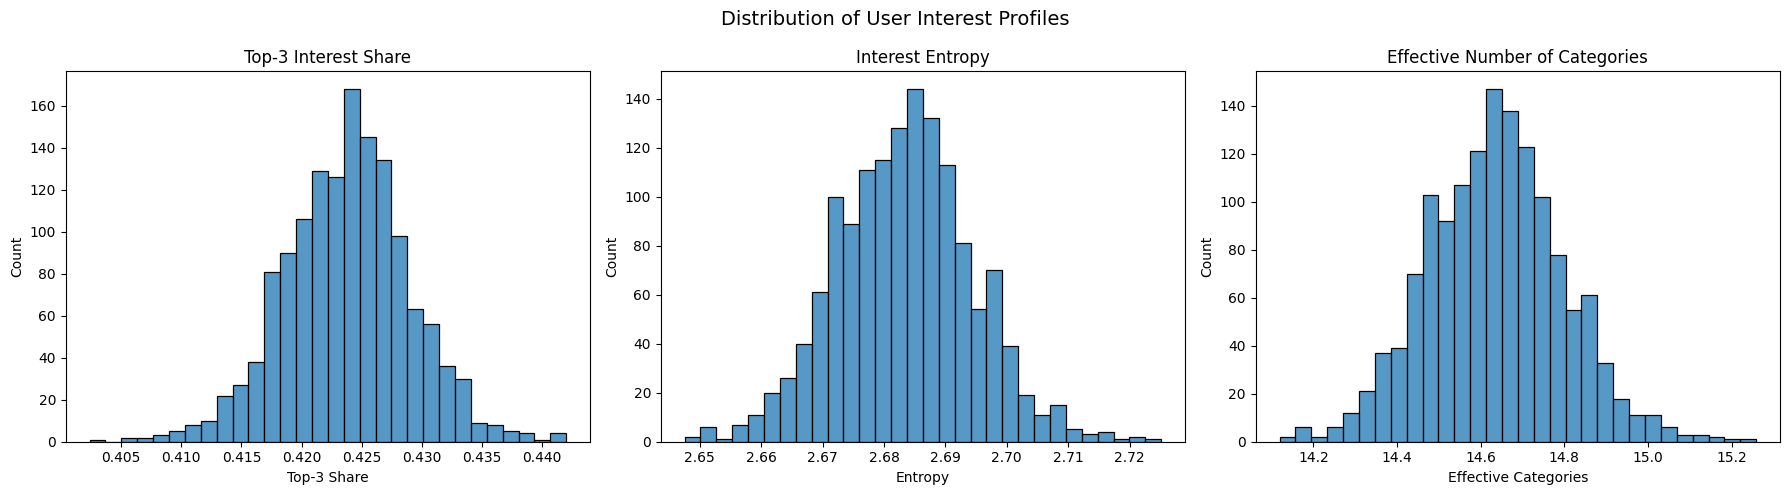

In [19]:
# Cell 17: Visualise user interest concentration metrics

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    user_interest_metrics["top_3_interest_share"],
    bins=30,
    ax=axes[0]
)
axes[0].set_title("Top-3 Interest Share")
axes[0].set_xlabel("Top-3 Share")

sns.histplot(
    user_interest_metrics["interest_entropy"],
    bins=30,
    ax=axes[1]
)
axes[1].set_title("Interest Entropy")
axes[1].set_xlabel("Entropy")

sns.histplot(
    user_interest_metrics["effective_categories"],
    bins=30,
    ax=axes[2]
)
axes[2].set_title("Effective Number of Categories")
axes[2].set_xlabel("Effective Categories")

plt.suptitle("Distribution of User Interest Profiles", fontsize=14)
plt.tight_layout()
plt.show()

In [20]:
# Cell 18: Compare individual profiles with the global interest profile

# Create user-category matrix
user_interest_matrix = user_category_interest.pivot(
    index="user_id",
    columns="category_id",
    values="interest_weight"
).fillna(0)

# Average category-interest profile across users
global_interest_profile = user_interest_matrix.mean(axis=0)

# Calculate cosine similarity between each user and the global profile
user_global_similarity = user_interest_matrix.apply(
    lambda row: np.dot(row, global_interest_profile) /
    (np.linalg.norm(row) * np.linalg.norm(global_interest_profile)),
    axis=1
)

print("User-global profile cosine similarity:")
display(user_global_similarity.describe())

print("\nMean similarity to global profile:",
      round(user_global_similarity.mean(), 6))

print("\nUsers with lowest similarity to global profile:")
display(user_global_similarity.sort_values().head(10))

print("\nUsers with highest similarity to global profile:")
display(user_global_similarity.sort_values(ascending=False).head(10))

User-global profile cosine similarity:


count    1411.000000
mean        0.999489
std         0.000462
min         0.995519
25%         0.999334
50%         0.999625
75%         0.999797
max         0.999962
dtype: float64


Mean similarity to global profile: 0.999489

Users with lowest similarity to global profile:


user_id
5893    0.995519
1457    0.995775
4479    0.996596
6111    0.996893
7056    0.996941
23      0.997002
2108    0.997226
1257    0.997399
1029    0.997446
5552    0.997467
dtype: float64


Users with highest similarity to global profile:


user_id
1653    0.999962
4678    0.999960
2205    0.999959
3464    0.999956
2005    0.999955
3789    0.999953
6122    0.999950
3404    0.999947
5158    0.999947
5342    0.999945
dtype: float64

In [21]:
# Cell 19: Measure category-level variation across users

category_profile_variation = (
    user_interest_matrix.std(axis=0)
    .sort_values(ascending=False)
    .reset_index()
)

category_profile_variation.columns = [
    "category_id",
    "interest_weight_std"
]

print("Categories with the greatest variation across users:")
display(category_profile_variation.head(15))

print("\nCategories with the least variation across users:")
display(category_profile_variation.tail(10))

print("\nOverall category variation:")
display(category_profile_variation["interest_weight_std"].describe())

Categories with the greatest variation across users:


,category_id,interest_weight_std
0,28,0.006071
1,8,0.003518
2,6,0.003492
3,7,0.002302
4,9,0.002275
5,26,0.002168
6,15,0.002149
7,11,0.002118
8,17,0.002115
9,12,0.002113



Categories with the least variation across users:


,category_id,interest_weight_std
21,21,0.000323
22,30,0.000281
23,13,0.000242
24,0,0.000229
25,3,0.000222
26,27,0.000199
27,29,0.000152
28,22,0.000119
29,23,0.000078
30,24,0.000061



Overall category variation:


count    31.000000
mean      0.001333
std       0.001326
min       0.000061
25%       0.000262
50%       0.001092
75%       0.002117
max       0.006071
Name: interest_weight_std, dtype: float64

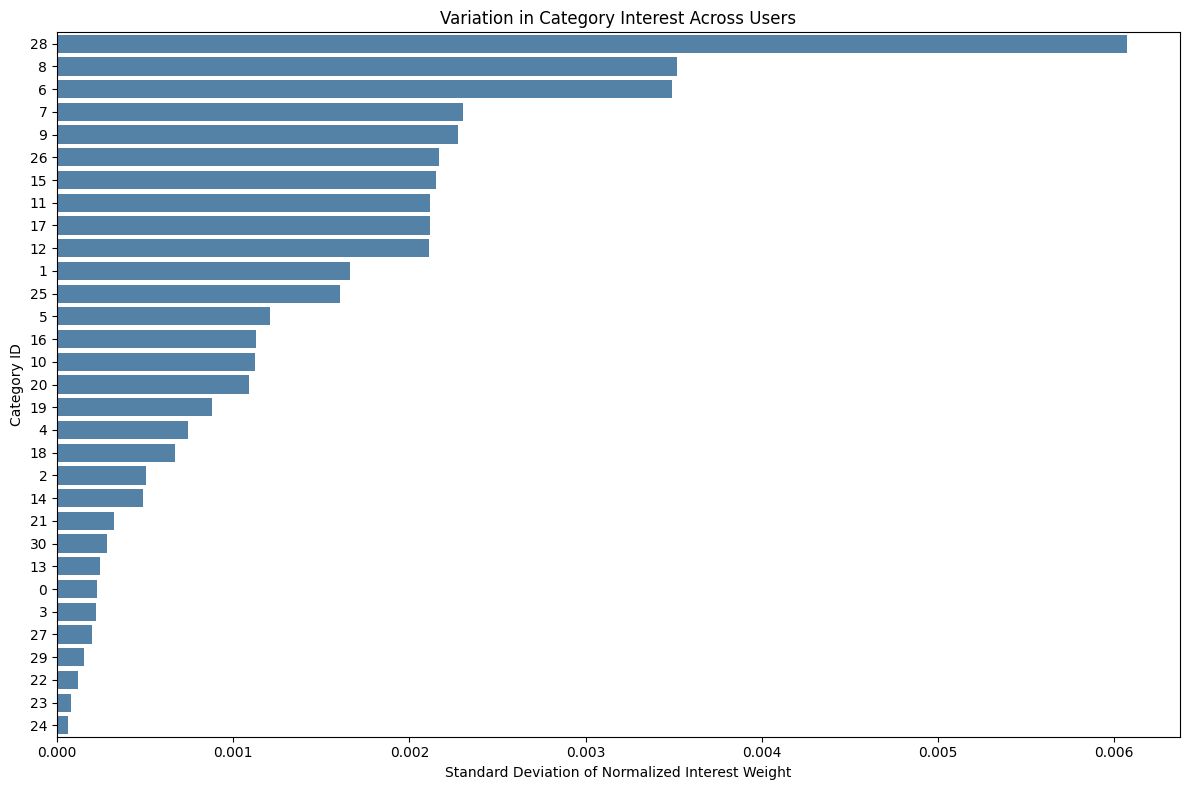

In [22]:
# Cell 20: Visualise category-level variation across users

variation_plot = category_profile_variation.copy()
variation_plot["category_id"] = variation_plot["category_id"].astype(str)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=variation_plot,
    x="interest_weight_std",
    y="category_id",
    color="steelblue",
    errorbar=None
)

plt.title("Variation in Category Interest Across Users")
plt.xlabel("Standard Deviation of Normalized Interest Weight")
plt.ylabel("Category ID")
plt.tight_layout()
plt.show()

In [23]:
# Cell 21: Analyse dominant categories across users

# Identify each user's highest-interest category
user_top_category = (
    user_category_interest
    .sort_values(
        ["user_id", "interest_weight"],
        ascending=[True, False]
    )
    .groupby("user_id")
    .first()
    .reset_index()
)

# Count how often each category is the dominant interest
dominant_category_distribution = (
    user_top_category["category_id"]
    .value_counts()
    .rename_axis("category_id")
    .reset_index(name="user_count")
)

dominant_category_distribution["percentage"] = (
    dominant_category_distribution["user_count"] /
    len(user_top_category) * 100
)

dominant_category_distribution = dominant_category_distribution.sort_values(
    "user_count", ascending=False
)

print("Number of users analysed:", len(user_top_category))

print("\nDominant category distribution:")
display(dominant_category_distribution)

print("\nMost common dominant category:")
display(dominant_category_distribution.head(10))

print("\nNumber of categories represented as users' dominant interest:",
      dominant_category_distribution["category_id"].nunique())

Number of users analysed: 1411

Dominant category distribution:


,category_id,user_count,percentage
0,28,1411,100.0



Most common dominant category:


,category_id,user_count,percentage
0,28,1411,100.0



Number of categories represented as users' dominant interest: 1


In [26]:
# Cell 22A: Safely inspect loaded notebook variables

current_variables = list(globals().keys())

print("expanded_interest_data exists:",
      "expanded_interest_data" in current_variables)

print("\nAvailable interest-related variables:")
for variable in current_variables:
    if "interest" in variable.lower() or "category" in variable.lower():
        print(variable)

expanded_interest_data exists: False

Available interest-related variables:
valid_category_ids
category_video_counts
interest_interactions
interest_data
user_category_interactions
user_category_interest
user_category_counts
category_average_interest
user_interest_metrics
user_interest_matrix
global_interest_profile
category_profile_variation
user_top_category
dominant_category_distribution


In [27]:
# Cell 22B: Inspect existing interest-related datasets

datasets_to_check = [
    "interest_data",
    "interest_interactions",
    "user_category_interactions"
]

for dataset_name in datasets_to_check:
    dataset = globals()[dataset_name]

    print(f"\n{'=' * 50}")
    print(f"Dataset: {dataset_name}")
    print("Shape:", dataset.shape)
    print("Columns:", dataset.columns.tolist())
    display(dataset.head(3))


Dataset: interest_data
Shape: (4387382, 6)
Columns: ['user_id', 'video_id', 'watch_ratio', 'preference_score', 'category_ids', 'category_count']


,user_id,video_id,watch_ratio,preference_score,category_ids,category_count
0,14,148,0.722103,0.722103,"[11, 28, 19]",3
1,14,183,1.907377,1.000000,[28],1
2,14,3649,2.063311,1.000000,[9],1



Dataset: interest_interactions
Shape: (4387382, 4)
Columns: ['user_id', 'video_id', 'watch_ratio', 'preference_score']


,user_id,video_id,watch_ratio,preference_score
0,14,148,0.722103,0.722103
1,14,183,1.907377,1.000000
2,14,3649,2.063311,1.000000



Dataset: user_category_interactions
Shape: (6063117, 7)
Columns: ['user_id', 'video_id', 'watch_ratio', 'preference_score', 'category_ids', 'category_count', 'category_contribution']


,user_id,video_id,watch_ratio,preference_score,category_ids,category_count,category_contribution
0,14,148,0.722103,0.722103,11,3,0.240701
0,14,148,0.722103,0.722103,28,3,0.240701
0,14,148,0.722103,0.722103,19,3,0.240701


In [28]:
# Cell 22: Calculate category interests using mean preference

user_category_mean_preference = (
    user_category_interactions
    .groupby(["user_id", "category_ids"])["preference_score"]
    .mean()
    .reset_index(name="mean_category_preference")
)

# Normalize category preferences within each user
user_category_mean_preference["interest_weight"] = (
    user_category_mean_preference
    .groupby("user_id")["mean_category_preference"]
    .transform(lambda x: x / x.sum())
)

print("Mean-preference interest dataset shape:",
      user_category_mean_preference.shape)

print("\nSample:")
display(user_category_mean_preference.head(10))

print("\nNormalized profile sum validation:")
profile_sums = (
    user_category_mean_preference
    .groupby("user_id")["interest_weight"]
    .sum()
)

display(profile_sums.describe())

print("\nProfiles not summing to 1:",
      (np.abs(profile_sums - 1) > 1e-6).sum())

Mean-preference interest dataset shape: (43707, 4)

Sample:


,user_id,category_ids,mean_category_preference,interest_weight
0,14,0,0.701592,0.032793
1,14,1,0.763993,0.035709
2,14,2,0.620291,0.028993
3,14,3,0.553769,0.025883
4,14,4,0.735436,0.034375
5,14,5,0.767601,0.035878
6,14,6,0.656392,0.030680
7,14,7,0.814710,0.038080
8,14,8,0.757394,0.035401
9,14,9,0.725393,0.033905



Normalized profile sum validation:


count    1.411000e+03
mean     1.000000e+00
std      1.467347e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: interest_weight, dtype: float64


Profiles not summing to 1: 0


In [29]:
# Cell 23: Analyse dominant categories using mean preference

user_mean_top_category = (
    user_category_mean_preference
    .sort_values(
        ["user_id", "interest_weight"],
        ascending=[True, False]
    )
    .groupby("user_id")
    .first()
    .reset_index()
)

mean_dominant_category_distribution = (
    user_mean_top_category["category_ids"]
    .value_counts()
    .rename_axis("category_id")
    .reset_index(name="user_count")
)

mean_dominant_category_distribution["percentage"] = (
    mean_dominant_category_distribution["user_count"]
    / len(user_mean_top_category) * 100
)

print("Users analysed:", len(user_mean_top_category))

print("\nDominant category distribution (mean preference):")
display(mean_dominant_category_distribution)

print("\nNumber of distinct dominant categories:",
      mean_dominant_category_distribution["category_id"].nunique())

Users analysed: 1411

Dominant category distribution (mean preference):


,category_id,user_count,percentage
0,24,1001,70.942594
1,23,90,6.378455
2,13,74,5.244507
3,28,66,4.677534
4,18,65,4.606662
5,29,24,1.700921
6,14,18,1.275691
7,5,15,1.063076
8,7,12,0.850461
9,3,11,0.779589



Number of distinct dominant categories: 18


In [31]:
# Cell 24: Investigate Category 24 dominance

# Calculate catalogue video counts by category
catalogue_category_counts = (
    video_metadata
    .explode("category_ids")
    .groupby("category_ids")["video_id"]
    .nunique()
    .reset_index(name="catalogue_video_count")
)

# Calculate interaction-level category statistics
category_diagnostics = (
    user_category_interactions
    .groupby("category_ids")
    .agg(
        interaction_count=("user_id", "size"),
        unique_users=("user_id", "nunique"),
        unique_videos=("video_id", "nunique"),
        mean_preference=("preference_score", "mean"),
        mean_category_contribution=("category_contribution", "mean")
    )
    .reset_index()
)

# Merge catalogue availability
category_diagnostics = category_diagnostics.merge(
    catalogue_category_counts,
    on="category_ids",
    how="left"
)

category_diagnostics = category_diagnostics.sort_values(
    "unique_users",
    ascending=False
).reset_index(drop=True)

# Inspect Category 24 specifically
print("Category 24 diagnostics:")
display(
    category_diagnostics[
        category_diagnostics["category_ids"] == 24
    ]
)

# Compare Category 24 with the 10 most widely interacted categories
print("\nTop 10 categories by unique users:")
display(category_diagnostics.head(10))

Category 24 diagnostics:


,category_ids,interaction_count,unique_users,unique_videos,mean_preference,mean_category_contribution,catalogue_video_count
30,24,1380,1380,1,0.861852,0.430926,1



Top 10 categories by unique users:


,category_ids,interaction_count,unique_users,unique_videos,mean_preference,mean_category_contribution,catalogue_video_count
0,0,13371,1411,11,0.637114,0.323839,11
1,1,219993,1411,163,0.725535,0.530529,163
2,2,40820,1411,31,0.634689,0.399357,31
3,3,8752,1411,7,0.504540,0.390552,7
4,4,48661,1411,37,0.722416,0.585482,37
5,5,134460,1411,100,0.748691,0.501755,100
6,6,594214,1411,447,0.611161,0.473407,451
7,7,279070,1411,207,0.762003,0.664853,208
8,8,688967,1411,505,0.725073,0.507203,506
9,9,431835,1411,327,0.684289,0.388159,332


In [32]:
# Cell 25: Inspect the video associated with Category 24

category_24_video_ids = (
    user_category_interactions.loc[
        user_category_interactions["category_ids"] == 24,
        "video_id"
    ]
    .unique()
)

print("Videos assigned to Category 24:", category_24_video_ids)

# Inspect metadata for the video
category_24_metadata = video_metadata[
    video_metadata["video_id"].isin(category_24_video_ids)
]

display(category_24_metadata)

# Inspect interaction behaviour for this video
category_24_interactions = training_interactions[
    training_interactions["video_id"].isin(category_24_video_ids)
]

print("\nCategory 24 video interaction statistics:")
print("Total interactions:", len(category_24_interactions))
print("Unique users:", category_24_interactions["user_id"].nunique())

display(
    category_24_interactions["watch_ratio"].describe()
)


Videos assigned to Category 24: [4359]


,video_id,category_ids,category_count,manual_cover_text,caption,topic_tag,first_level_category_id,first_level_category_name,second_level_category_id,second_level_category_name,third_level_category_id,third_level_category_name
1554,4359,"[24, 11]",2,ing情侣头像,🌝,[],19.0,情感,744.0,情感关系,-124.0,UNKNOWN


NameError: name 'training_interactions' is not defined

In [33]:
# Inspect interaction behaviour using interest_data

category_24_interactions = interest_data[
    interest_data["video_id"].isin(category_24_video_ids)
]

print("\nCategory 24 video interaction statistics:")
print("Total interactions:", len(category_24_interactions))
print("Unique users:", category_24_interactions["user_id"].nunique())

print("\nWatch ratio statistics:")
display(category_24_interactions["watch_ratio"].describe())

print("\nPreference score statistics:")
display(category_24_interactions["preference_score"].describe())


Category 24 video interaction statistics:
Total interactions: 1380
Unique users: 1380

Watch ratio statistics:


count    1380.000000
mean        1.162964
std         1.163380
min         0.000000
25%         0.808865
50%         1.077321
75%         1.371470
max        34.667226
Name: watch_ratio, dtype: float64


Preference score statistics:


count    1380.000000
mean        0.861852
std         0.235385
min         0.000000
25%         0.808865
50%         1.000000
75%         1.000000
max         1.000000
Name: preference_score, dtype: float64

In [34]:
# Cell 26: Reliability-adjusted category interest

# Calculate user-category preference and support
user_category_reliability = (
    user_category_interactions
    .groupby(["user_id", "category_ids"])
    .agg(
        mean_user_preference=("preference_score", "mean"),
        unique_videos=("video_id", "nunique")
    )
    .reset_index()
)

# Calculate category-level prior
category_prior = (
    user_category_reliability
    .groupby("category_ids")["mean_user_preference"]
    .mean()
    .reset_index(name="category_prior")
)

# Merge category prior
user_category_reliability = user_category_reliability.merge(
    category_prior,
    on="category_ids",
    how="left"
)

# Smoothing parameter
m = 5

# Reliability-adjusted preference
user_category_reliability["adjusted_interest"] = (
    (
        user_category_reliability["unique_videos"]
        / (user_category_reliability["unique_videos"] + m)
    )
    * user_category_reliability["mean_user_preference"]
    +
    (
        m
        / (user_category_reliability["unique_videos"] + m)
    )
    * user_category_reliability["category_prior"]
)

# Normalize scores within each user
user_category_reliability["interest_weight"] = (
    user_category_reliability
    .groupby("user_id")["adjusted_interest"]
    .transform(lambda x: x / x.sum())
)

print("Reliability-adjusted profile shape:",
      user_category_reliability.shape)

print("\nSample:")
display(user_category_reliability.head(10))

# Validate normalization
reliability_profile_sums = (
    user_category_reliability
    .groupby("user_id")["interest_weight"]
    .sum()
)

print("\nProfile normalization:")
display(reliability_profile_sums.describe())

print("\nProfiles not summing to 1:",
      (np.abs(reliability_profile_sums - 1) > 1e-6).sum())

Reliability-adjusted profile shape: (43707, 7)

Sample:


,user_id,category_ids,mean_user_preference,unique_videos,category_prior,adjusted_interest,interest_weight
0,14,0,0.701592,10,0.639001,0.680728,0.032257
1,14,1,0.763993,156,0.725156,0.762787,0.036145
2,14,2,0.620291,30,0.635009,0.622393,0.029492
3,14,3,0.553769,4,0.513945,0.531645,0.025192
4,14,4,0.735436,35,0.722665,0.733839,0.034773
5,14,5,0.767601,97,0.748461,0.766663,0.036329
6,14,6,0.656392,434,0.611229,0.655877,0.031079
7,14,7,0.814710,194,0.761928,0.813384,0.038542
8,14,8,0.757394,492,0.724638,0.757064,0.035874
9,14,9,0.725393,316,0.684580,0.724757,0.034343



Profile normalization:


count    1.411000e+03
mean     1.000000e+00
std      1.537745e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: interest_weight, dtype: float64


Profiles not summing to 1: 0


In [35]:
# Cell 27: Analyse dominant categories in reliability-adjusted profiles

reliability_top_category = (
    user_category_reliability
    .sort_values(
        ["user_id", "interest_weight"],
        ascending=[True, False]
    )
    .groupby("user_id")
    .first()
    .reset_index()
)

reliability_dominant_distribution = (
    reliability_top_category["category_ids"]
    .value_counts()
    .rename_axis("category_id")
    .reset_index(name="user_count")
)

reliability_dominant_distribution["percentage"] = (
    reliability_dominant_distribution["user_count"]
    / len(reliability_top_category) * 100
)

print("Users analysed:", len(reliability_top_category))

print("\nDominant category distribution (reliability-adjusted):")
display(reliability_dominant_distribution)

print("\nDistinct dominant categories:",
      reliability_dominant_distribution["category_id"].nunique())

print("\nUsers with Category 24 as dominant interest:")
print(
    reliability_dominant_distribution.loc[
        reliability_dominant_distribution["category_id"] == 24,
        "user_count"
    ].sum()
)

Users analysed: 1411

Dominant category distribution (reliability-adjusted):


,category_id,user_count,percentage
0,24,1227,86.959603
1,28,64,4.535790
2,18,37,2.622254
3,13,37,2.622254
4,7,22,1.559178
5,14,6,0.425230
6,5,6,0.425230
7,10,3,0.212615
8,4,3,0.212615
9,1,2,0.141743



Distinct dominant categories: 14

Users with Category 24 as dominant interest:
1227


In [37]:
# Cell 28: Examine category priors and support

category_prior_diagnostics = (
    user_category_reliability
    .groupby("category_ids")
    .agg(
        category_prior=("category_prior", "first"),
        mean_user_preference=("mean_user_preference", "mean"),
        mean_adjusted_interest=("adjusted_interest", "mean"),
        user_count=("user_id", "nunique"),
        video_support=("unique_videos", "mean")
    )
    .reset_index()
    .sort_values("category_prior", ascending=False)
)

print("Category 24 prior:")
display(
    category_prior_diagnostics[
        category_prior_diagnostics["category_ids"] == 24
    ]
)

print("\nHighest category priors:")
display(category_prior_diagnostics.head(10))

print("\nLowest category priors:")
display(category_prior_diagnostics.tail(10))

Category 24 prior:


,category_ids,category_prior,mean_user_preference,mean_adjusted_interest,user_count,video_support
24,24,0.861852,0.861852,0.861852,1380,1.0



Highest category priors:


,category_ids,category_prior,mean_user_preference,mean_adjusted_interest,user_count,video_support
24,24,0.861852,0.861852,0.861852,1380,1.000000
28,28,0.773367,0.773367,0.773368,1411,777.391212
7,7,0.761928,0.761928,0.761930,1411,197.781715
18,18,0.757973,0.757973,0.757965,1411,34.109142
5,5,0.748461,0.748461,0.748473,1411,95.294118
13,13,0.747440,0.747440,0.747469,1411,11.377746
17,17,0.745828,0.745828,0.745822,1411,176.359320
1,1,0.725156,0.725156,0.725168,1411,155.912828
8,8,0.724638,0.724638,0.724643,1411,488.282778
4,4,0.722665,0.722665,0.722635,1411,34.486889



Lowest category priors:


,category_ids,category_prior,mean_user_preference,mean_adjusted_interest,user_count,video_support
6,6,0.611229,0.611229,0.611228,1411,421.129695
29,29,0.600309,0.600309,0.599811,1411,4.695960
21,21,0.597494,0.597494,0.597003,1411,9.098512
23,23,0.593779,0.593779,0.594301,1409,1.909155
3,3,0.513945,0.513945,0.511159,1411,6.202693
27,27,0.512454,0.512454,0.512103,1411,8.645641
12,12,0.489655,0.489655,0.489638,1411,137.706591
16,16,0.477112,0.477112,0.476915,1411,56.892984
30,30,0.364151,0.364151,0.363397,1411,10.802268
22,22,0.154299,0.154299,0.154329,1410,4.600000


In [38]:
# Cell 29: Filter poorly supported categories and reconstruct interest profiles

MIN_CATEGORY_VIDEOS = 5

# Identify categories meeting minimum catalogue support
eligible_categories = catalogue_category_counts[
    catalogue_category_counts["catalogue_video_count"]
    >= MIN_CATEGORY_VIDEOS
]["category_ids"]

print("Eligible categories:", len(eligible_categories))
print("Excluded categories:",
      len(catalogue_category_counts) - len(eligible_categories))

# Filter the mean-preference profiles
filtered_interest_profiles = (
    user_category_mean_preference[
        user_category_mean_preference["category_ids"].isin(
            eligible_categories
        )
    ]
    .copy()
)

# Renormalize remaining categories within each user
filtered_interest_profiles["interest_weight"] = (
    filtered_interest_profiles
    .groupby("user_id")["mean_category_preference"]
    .transform(lambda x: x / x.sum())
)

# Validate user coverage and normalization
filtered_profile_sums = (
    filtered_interest_profiles
    .groupby("user_id")["interest_weight"]
    .sum()
)

print("\nFiltered profile shape:", filtered_interest_profiles.shape)
print("Users retained:", filtered_interest_profiles["user_id"].nunique())

print("\nNormalization validation:")
display(filtered_profile_sums.describe())

print("\nProfiles not summing to 1:",
      (np.abs(filtered_profile_sums - 1) > 1e-6).sum())

# Analyse dominant category after filtering
filtered_top_categories = (
    filtered_interest_profiles
    .sort_values(
        ["user_id", "interest_weight"],
        ascending=[True, False]
    )
    .groupby("user_id")
    .first()
    .reset_index()
)

filtered_dominant_distribution = (
    filtered_top_categories["category_ids"]
    .value_counts()
    .rename_axis("category_id")
    .reset_index(name="user_count")
)

filtered_dominant_distribution["percentage"] = (
    filtered_dominant_distribution["user_count"]
    / len(filtered_top_categories) * 100
)

print("\nDominant categories after minimum-support filtering:")
display(filtered_dominant_distribution)

print("\nDistinct dominant categories:",
      filtered_dominant_distribution["category_id"].nunique())

Eligible categories: 29
Excluded categories: 2

Filtered profile shape: (40918, 4)
Users retained: 1411

Normalization validation:


count    1.411000e+03
mean     1.000000e+00
std      1.386479e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: interest_weight, dtype: float64


Profiles not summing to 1: 0

Dominant categories after minimum-support filtering:


,category_id,user_count,percentage
0,28,379,26.860383
1,13,339,24.025514
2,18,250,17.717931
3,7,122,8.646350
4,29,62,4.394047
5,5,60,4.252303
6,14,45,3.189227
7,4,41,2.905741
8,0,31,2.197023
9,3,28,1.984408



Distinct dominant categories: 17


In [39]:
# Cell 29: Filter poorly supported categories and reconstruct interest profiles

MIN_CATEGORY_VIDEOS = 5

# Identify categories meeting minimum catalogue support
eligible_categories = catalogue_category_counts[
    catalogue_category_counts["catalogue_video_count"]
    >= MIN_CATEGORY_VIDEOS
]["category_ids"]

print("Eligible categories:", len(eligible_categories))
print("Excluded categories:",
      len(catalogue_category_counts) - len(eligible_categories))

# Filter the mean-preference profiles
filtered_interest_profiles = (
    user_category_mean_preference[
        user_category_mean_preference["category_ids"].isin(
            eligible_categories
        )
    ]
    .copy()
)

# Renormalize remaining categories within each user
filtered_interest_profiles["interest_weight"] = (
    filtered_interest_profiles
    .groupby("user_id")["mean_category_preference"]
    .transform(lambda x: x / x.sum())
)

# Validate user coverage and normalization
filtered_profile_sums = (
    filtered_interest_profiles
    .groupby("user_id")["interest_weight"]
    .sum()
)

print("\nFiltered profile shape:", filtered_interest_profiles.shape)
print("Users retained:", filtered_interest_profiles["user_id"].nunique())

print("\nNormalization validation:")
display(filtered_profile_sums.describe())

print("\nProfiles not summing to 1:",
      (np.abs(filtered_profile_sums - 1) > 1e-6).sum())

# Analyse dominant category after filtering
filtered_top_categories = (
    filtered_interest_profiles
    .sort_values(
        ["user_id", "interest_weight"],
        ascending=[True, False]
    )
    .groupby("user_id")
    .first()
    .reset_index()
)

filtered_dominant_distribution = (
    filtered_top_categories["category_ids"]
    .value_counts()
    .rename_axis("category_id")
    .reset_index(name="user_count")
)

filtered_dominant_distribution["percentage"] = (
    filtered_dominant_distribution["user_count"]
    / len(filtered_top_categories) * 100
)

print("\nDominant categories after minimum-support filtering:")
display(filtered_dominant_distribution)

print("\nDistinct dominant categories:",
      filtered_dominant_distribution["category_id"].nunique())

Eligible categories: 29
Excluded categories: 2

Filtered profile shape: (40918, 4)
Users retained: 1411

Normalization validation:


count    1.411000e+03
mean     1.000000e+00
std      1.386479e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: interest_weight, dtype: float64


Profiles not summing to 1: 0

Dominant categories after minimum-support filtering:


,category_id,user_count,percentage
0,28,379,26.860383
1,13,339,24.025514
2,18,250,17.717931
3,7,122,8.646350
4,29,62,4.394047
5,5,60,4.252303
6,14,45,3.189227
7,4,41,2.905741
8,0,31,2.197023
9,3,28,1.984408



Distinct dominant categories: 17


In [40]:
# Cell 30: Compare interest-profile concentration

def calculate_profile_concentration(profile_df, weight_col="interest_weight"):
    results = []

    for user_id, group in profile_df.groupby("user_id"):
        weights = group[weight_col].values
        weights = weights[weights > 0]

        sorted_weights = np.sort(weights)[::-1]

        top3_share = sorted_weights[:3].sum()
        entropy = -np.sum(weights * np.log(weights))
        effective_categories = np.exp(entropy)

        results.append({
            "user_id": user_id,
            "top3_share": top3_share,
            "entropy": entropy,
            "effective_categories": effective_categories
        })

    return pd.DataFrame(results)


original_concentration = calculate_profile_concentration(
    user_category_interest
)

filtered_concentration = calculate_profile_concentration(
    filtered_interest_profiles
)

concentration_comparison = pd.DataFrame({
    "Metric": [
        "Top-3 Interest Share",
        "Entropy",
        "Effective Categories"
    ],
    "Original Mean": [
        original_concentration["top3_share"].mean(),
        original_concentration["entropy"].mean(),
        original_concentration["effective_categories"].mean()
    ],
    "Filtered Mean": [
        filtered_concentration["top3_share"].mean(),
        filtered_concentration["entropy"].mean(),
        filtered_concentration["effective_categories"].mean()
    ]
})

display(concentration_comparison)

print("\nOriginal profile statistics:")
display(original_concentration.describe())

print("\nFiltered profile statistics:")
display(filtered_concentration.describe())

,Metric,Original Mean,Filtered Mean
0,Top-3 Interest Share,0.423762,0.127166
1,Entropy,2.683327,3.336091
2,Effective Categories,14.634599,28.109623



Original profile statistics:


,user_id,top3_share,entropy,effective_categories
count,1411.000000,1411.000000,1411.000000,1411.000000
mean,3631.627923,0.423762,2.683327,14.634599
std,2044.494719,0.005279,0.011131,0.162973
min,14.000000,0.402385,2.647527,14.119080
25%,1835.000000,0.420287,2.675695,14.522435
50%,3687.000000,0.423962,2.683542,14.636852
75%,5419.000000,0.427096,2.690440,14.738155
max,7162.000000,0.441994,2.725150,15.258703



Filtered profile statistics:


,user_id,top3_share,entropy,effective_categories
count,1411.000000,1411.000000,1411.000000,1411.000000
mean,3631.627923,0.127166,3.336091,28.109623
std,2044.494719,0.004135,0.006451,0.180628
min,14.000000,0.116930,3.272276,26.371284
25%,1835.000000,0.124611,3.332843,28.017870
50%,3687.000000,0.126725,3.335917,28.104142
75%,5419.000000,0.128863,3.339345,28.200647
max,7162.000000,0.154993,3.358909,28.757801


In [42]:
# Cell 31A: Inspect dataframe columns

print("Original profile dataframe:")
print(user_category_interest.columns.tolist())

print("\nFiltered profile dataframe:")
print(filtered_interest_profiles.columns.tolist())

print("\nOriginal dataframe shape:", user_category_interest.shape)
print("Filtered dataframe shape:", filtered_interest_profiles.shape)

Original profile dataframe:
['user_id', 'category_id', 'interest_score', 'interest_weight']

Filtered profile dataframe:
['user_id', 'category_ids', 'mean_category_preference', 'interest_weight']

Original dataframe shape: (43707, 4)
Filtered dataframe shape: (40918, 4)


In [43]:
# Cell 31: Evaluate user-level personalization

# Create user-category matrices
original_profile_matrix = (
    user_category_interest
    .pivot(
        index="user_id",
        columns="category_id",
        values="interest_weight"
    )
    .fillna(0)
)

filtered_profile_matrix = (
    filtered_interest_profiles
    .pivot(
        index="user_id",
        columns="category_ids",
        values="interest_weight"
    )
    .fillna(0)
)

# Measure category variation across users
original_category_variation = original_profile_matrix.std(axis=0)
filtered_category_variation = filtered_profile_matrix.std(axis=0)

print("Original profile matrix:", original_profile_matrix.shape)
print("Filtered profile matrix:", filtered_profile_matrix.shape)

print("\nMean category variation across users:")
print("Original:", original_category_variation.mean())
print("Filtered:", filtered_category_variation.mean())

print("\nOriginal category variation:")
display(original_category_variation.describe())

print("\nFiltered category variation:")
display(filtered_category_variation.describe())

# Sample user pairs
rng = np.random.default_rng(42)

user_ids = filtered_profile_matrix.index.to_numpy()
pair_count = 10000

user_pairs = rng.choice(user_ids, size=(pair_count, 2), replace=True)

# Convert matrices to arrays
original_matrix = original_profile_matrix.reindex(user_ids).to_numpy()
filtered_matrix = filtered_profile_matrix.to_numpy()

# Normalize rows
original_norms = np.linalg.norm(original_matrix, axis=1, keepdims=True)
filtered_norms = np.linalg.norm(filtered_matrix, axis=1, keepdims=True)

original_normalized = original_matrix / np.maximum(original_norms, 1e-12)
filtered_normalized = filtered_matrix / np.maximum(filtered_norms, 1e-12)

# Map user IDs to matrix positions
user_positions = {user_id: i for i, user_id in enumerate(user_ids)}

pair_indices = np.array([
    [user_positions[u1], user_positions[u2]]
    for u1, u2 in user_pairs
])

# Calculate cosine similarity
original_pair_similarity = np.sum(
    original_normalized[pair_indices[:, 0]]
    * original_normalized[pair_indices[:, 1]],
    axis=1
)

filtered_pair_similarity = np.sum(
    filtered_normalized[pair_indices[:, 0]]
    * filtered_normalized[pair_indices[:, 1]],
    axis=1
)

# Exclude same-user pairs
different_user_mask = user_pairs[:, 0] != user_pairs[:, 1]

original_pair_similarity = original_pair_similarity[different_user_mask]
filtered_pair_similarity = filtered_pair_similarity[different_user_mask]

print("\nCosine similarity between different users:")

print("\nOriginal profiles:")
display(pd.Series(original_pair_similarity).describe())

print("\nFiltered profiles:")
display(pd.Series(filtered_pair_similarity).describe())

Original profile matrix: (1411, 31)
Filtered profile matrix: (1411, 29)

Mean category variation across users:
Original: 0.0013332946940840795
Filtered: 0.002325537895880376

Original category variation:


count    31.000000
mean      0.001333
std       0.001326
min       0.000061
25%       0.000262
50%       0.001092
75%       0.002117
max       0.006071
dtype: float64


Filtered category variation:


count    29.000000
mean      0.002326
std       0.001392
min       0.000933
25%       0.001332
50%       0.001549
75%       0.003174
max       0.005806
dtype: float64


Cosine similarity between different users:

Original profiles:


count    9994.000000
mean        0.998966
std         0.000785
min         0.989460
25%         0.998677
50%         0.999184
75%         0.999494
max         0.999945
dtype: float64


Filtered profiles:


count    9994.000000
mean        0.994171
std         0.004610
min         0.956462
25%         0.992612
50%         0.995483
75%         0.997217
max         0.999629
dtype: float64

In [45]:
# Cell 32A: Inspect category catalogue counts

print("Columns:", catalogue_category_counts.columns.tolist())
print("Shape:", catalogue_category_counts.shape)

display(catalogue_category_counts.head(10))

Columns: ['category_ids', 'catalogue_video_count']
Shape: (31, 2)


,category_ids,catalogue_video_count
0,0,11
1,1,163
2,2,31
3,3,7
4,4,37
5,5,100
6,6,451
7,7,208
8,8,506
9,9,332


In [46]:
# Cell 32: Category support threshold sensitivity analysis

thresholds = [3, 5, 10]

sensitivity_results = []

for threshold in thresholds:

    # Identify eligible categories
    eligible_categories = catalogue_category_counts[
        catalogue_category_counts["catalogue_video_count"] >= threshold
    ]["category_ids"].tolist()

    # Filter user-category preferences
    threshold_profiles = user_category_mean_preference[
        user_category_mean_preference["category_ids"].isin(eligible_categories)
    ].copy()

    # Normalize profiles within each user
    threshold_profiles["interest_weight"] = (
        threshold_profiles["mean_category_preference"]
        / threshold_profiles.groupby("user_id")["mean_category_preference"].transform("sum")
    )

    # Calculate profile concentration
    concentration = calculate_profile_concentration(threshold_profiles)

    # Calculate dominant categories
    dominant_categories = threshold_profiles.loc[
        threshold_profiles.groupby("user_id")["interest_weight"].idxmax()
    ]

    sensitivity_results.append({
        "Minimum_Video_Support": threshold,
        "Eligible_Categories": len(eligible_categories),
        "Users_Retained": threshold_profiles["user_id"].nunique(),
        "Mean_Top3_Share": concentration["top3_share"].mean(),
        "Mean_Entropy": concentration["entropy"].mean(),
        "Mean_Effective_Categories": concentration["effective_categories"].mean(),
        "Dominant_Category_Count": dominant_categories["category_ids"].nunique()
    })

sensitivity_table = pd.DataFrame(sensitivity_results)

display(sensitivity_table.round(6))

,Minimum_Video_Support,Eligible_Categories,Users_Retained,Mean_Top3_Share,Mean_Entropy,Mean_Effective_Categories,Dominant_Category_Count
0,3,29,1411,0.127166,3.336091,28.109623,17
1,5,29,1411,0.127166,3.336091,28.109623,17
2,10,25,1411,0.140221,3.205244,24.661681,16


In [47]:
# Cell 33: Finalize interest profiles using minimum support = 5

MIN_CATEGORY_VIDEOS = 5

# Identify eligible categories
final_eligible_categories = catalogue_category_counts.loc[
    catalogue_category_counts["catalogue_video_count"] >= MIN_CATEGORY_VIDEOS,
    "category_ids"
].tolist()

# Filter user-category mean preferences
final_interest_profiles = user_category_mean_preference[
    user_category_mean_preference["category_ids"].isin(final_eligible_categories)
].copy()

# Normalize interests within each user
final_interest_profiles["interest_weight"] = (
    final_interest_profiles["mean_category_preference"]
    / final_interest_profiles.groupby("user_id")["mean_category_preference"].transform("sum")
)

# Validation
profile_sums = final_interest_profiles.groupby("user_id")["interest_weight"].sum()

print("Minimum category video support:", MIN_CATEGORY_VIDEOS)
print("Eligible categories:", len(final_eligible_categories))
print("Users represented:", final_interest_profiles["user_id"].nunique())
print("Final profile shape:", final_interest_profiles.shape)

print("\nProfile sum validation:")
print("Minimum profile sum:", profile_sums.min())
print("Maximum profile sum:", profile_sums.max())
print("Profiles not summing to 1:", (np.abs(profile_sums - 1) > 1e-10).sum())

print("\nMissing values:")
display(final_interest_profiles.isnull().sum())

# Save final interest profiles
final_interest_profiles.to_csv(
    os.path.join(PROCESSED_DIR, "interest_profiles.csv"),
    index=False
)

# Read back and verify
saved_interest_profiles = pd.read_csv(
    os.path.join(PROCESSED_DIR, "interest_profiles.csv")
)

print("\nSaved interest profiles successfully.")
print("Saved shape:", saved_interest_profiles.shape)
print("Saved users:", saved_interest_profiles["user_id"].nunique())
print("Saved categories:", saved_interest_profiles["category_ids"].nunique())

Minimum category video support: 5
Eligible categories: 29
Users represented: 1411
Final profile shape: (40918, 4)

Profile sum validation:
Minimum profile sum: 0.9999999999999999
Maximum profile sum: 1.0000000000000002
Profiles not summing to 1: 0

Missing values:


user_id                     0
category_ids                0
mean_category_preference    0
interest_weight             0
dtype: int64

NameError: name 'PROCESSED_DIR' is not defined

In [48]:
# Cell 33A: Check project directories

print("Current working directory:")
print(os.getcwd())

print("\nDirectories in current location:")
display(os.listdir())

Current working directory:
c:\Users\Shrutee Patil\Desktop\MSC Part 2 Sem 3\Research Project\Spotlight_project\notebooks

Directories in current location:


['01_data_exploration.ipynb',
 '02_baseline_recommender.ipynb',
 '03_interest_model.ipynb.ipynb',
 '04_fairness_model.ipynb',
 '05_exploration_strategy.ipynb',
 '06_evaluation.ipynb',
 '07_results_visualization.ipynb',
 '08_final_analysis.ipynb']

In [49]:
# Cell 33A: Save and verify finalized interest profiles

# Define correct path relative to notebooks folder
processed_dir = "../processed_data"

# Save final interest profiles
save_path = os.path.join(processed_dir, "interest_profiles.csv")

final_interest_profiles.to_csv(save_path, index=False)

# Read back the saved file
saved_interest_profiles = pd.read_csv(save_path)

print("Interest profiles saved successfully!")

print("\nFile path:", os.path.abspath(save_path))
print("Saved shape:", saved_interest_profiles.shape)
print("Saved users:", saved_interest_profiles["user_id"].nunique())
print("Saved categories:", saved_interest_profiles["category_ids"].nunique())

# Verify normalization after saving
saved_profile_sums = saved_interest_profiles.groupby("user_id")["interest_weight"].sum()

print("\nSaved profile validation:")
print("Minimum sum:", saved_profile_sums.min())
print("Maximum sum:", saved_profile_sums.max())
print("Invalid profiles:", (np.abs(saved_profile_sums - 1) > 1e-10).sum())

Interest profiles saved successfully!

File path: c:\Users\Shrutee Patil\Desktop\MSC Part 2 Sem 3\Research Project\Spotlight_project\processed_data\interest_profiles.csv
Saved shape: (40918, 4)
Saved users: 1411
Saved categories: 29

Saved profile validation:
Minimum sum: 0.9999999999999981
Maximum sum: 0.9999999999999993
Invalid profiles: 0


### Notebook 03: Interest Model — Summary

**Objective:** Develop user interest profiles that represent category-level preferences from historical watch behavior.

**Methodology:**
- Watch ratios were capped between 0 and 1 to create preference scores.
- Videos assigned to multiple categories had their preference contribution distributed across their categories.
- User-category preferences were aggregated.
- Category-level mean preferences were examined as an alternative representation.
- Categories with fewer than 5 catalogue videos were excluded.
- Profiles were normalized so each user's interest weights sum to 1.
- Category-support sensitivity was tested using thresholds of 3, 5, and 10 videos.

**Key findings:**
- 1,411 users retained.
- 29 eligible categories.
- 40,918 user-category profile records.
- Filtering substantially improved profile differentiation.
- Thresholds 3 and 5 produced identical results.
- Threshold 10 produced more concentrated profiles.

**Research implication:** Category-support filtering reduces the influence of poorly supported categories and produces more differentiated interest representations. The downstream impact on recommendation relevance, diversity, and creator exposure remains to be evaluated.

**Output:** `processed_data/interest_profiles.csv`

**Status:** Core interest-model construction completed and validated.